## Windows

### Frequency response

C:\Users\maxau\AppData\Local\Temp\ipykernel_9180\3549638804.py:15: RuntimeWarning: divide by zero encountered in log10
  response = 20 * np.log10(mag)


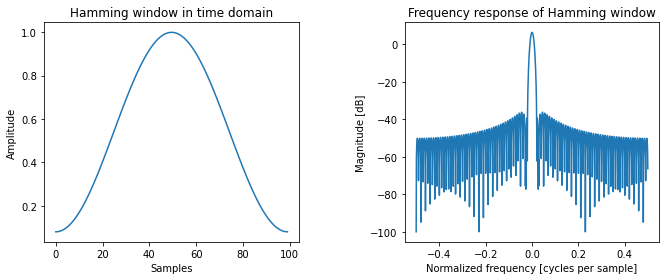

In [1]:
import matplotlib.pyplot as plt
import numpy as np

hamming = np.hamming(100)

fig,ax = plt.subplots(1,2)
ax[0].plot(hamming)
ax[0].set_title('Hamming window in time domain')
ax[0].set_xlabel('Samples')
ax[0].set_ylabel('Amplitude')

A = np.fft.fft(hamming, 2048) / 25.5
mag = np.abs(np.fft.fftshift(A))
freq = np.linspace(-0.5, 0.5, len(A))
response = 20 * np.log10(mag)
response = np.clip(response, -100, 100)
ax[1].plot(freq, response)
ax[1].set_title("Frequency response of Hamming window")
ax[1].set_ylabel("Magnitude [dB]")
ax[1].set_xlabel("Normalized frequency [cycles per sample]")
ax[1].axis('tight')

fig.tight_layout()
fig.set_size_inches(10,4)
plt.show()

### Windowing function properties

In [2]:
import pandas as pd
from scipy.signal import get_window

def compute_mainlobe_width(spectrum):
    """
    computes mainlobe width from spectrum
    
    assumes the mainlobe starts at 0, that spectrum size is odd, and that 
    the spectrum is real-valued (half of the frequencies)
    
    returns the number of samples of full mainlobe (not just half)
    """
    abs_spectrum = np.abs(spectrum)
    current_value = abs_spectrum[0]
    for ind, next_value in enumerate(abs_spectrum):
        if next_value > current_value:
            break
        else:
            current_value = next_value        
    return 2 * ind - 1

def compute_sidelobe_level(spectrum):
    """
    computes sidelobe level from spectrum

    assumes the mainlobe starts at 0, that spectrum size is odd, and that 
    the spectrum is real-valued (half of the frequencies)
    
    returns the level of sidelobes in dB 
    """
    mainlobe_width = compute_mainlobe_width(spectrum)
    
    ind = int((mainlobe_width - 1) / 2)
    
    abs_spectrum = np.abs(spectrum)
    
    return 20 * np.log10(abs_spectrum[ind:].max() / abs_spectrum.max())

props = {}
for window in ['boxcar', 'hanning', 'hamming', 'blackman', 'blackmanharris',10,11,12,13,20,50]:
    m = 513
    w = get_window(window, m)
    n = 4096
    w_fft = np.fft.rfft(w, n)
    freqs = np.fft.rfftfreq(n, d=1/m)
    width = compute_mainlobe_width(w_fft)
    width_bins = width * m / n
    level = compute_sidelobe_level(w_fft)
    props[window] = {'mainlobe width (bins)': width_bins,
                    'sidelobe level (dB)': level}
df = pd.DataFrame(props).transpose()
df

,mainlobe width (bins),sidelobe level (dB)
boxcar,2.129150,-13.383597
hanning,4.133057,-31.482269
hamming,4.133057,-42.676815
blackman,6.136963,-58.202942
blackmanharris,8.140869,-92.014585
10,6.888428,-74.172062
11,7.389404,-82.158195
12,8.140869,-90.798085
13,8.641846,-97.887160
20,13.401123,-160.760738


### Validation

In [3]:
import sys
sys.path.append('..')

from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import plotting as test_plot
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import pywt
import matplotlib.pyplot as plt

0       0.000038
1       0.000015
2       0.000016
3       0.000015
4       0.000016
          ...   
1019    0.000009
1020    0.000011
1021    0.000014
1022    0.000015
1023    0.000009
Name: energy, Length: 1024, dtype: object
0       0.000287
1       0.000013
2       0.000018
3       0.000023
4       0.000012
          ...   
1019    0.000013
1020    0.000017
1021    0.000012
1022    0.000009
1023    0.000013
Name: energy, Length: 1024, dtype: object
0       0.000064
1       0.000031
2       0.000013
3       0.000023
4       0.000013
          ...   
1019    0.000007
1020    0.000015
1021    0.000011
1022    0.000008
1023    0.000007
Name: energy, Length: 1024, dtype: object
0       0.000325
1       0.000083
2       0.000009
3       0.000016
4       0.000012
          ...   
1019    0.000008
1020    0.000011
1021    0.000011
1022    0.000008
1023    0.000008
Name: energy, Length: 1024, dtype: object
0       0.000443
1       0.000064
2       0.000009
3       0.000014
4       0.000009

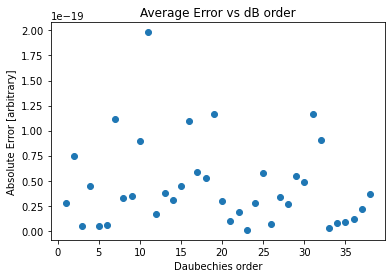

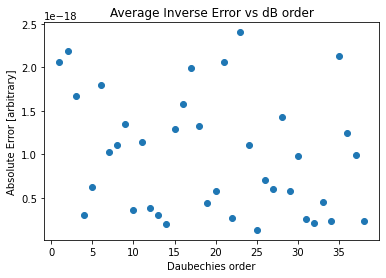

In [4]:
time = np.linspace(0,10,int(1e5))
data = np.sin(time)

for i in range(1500,1501):
    num = f'{i}'
    file = r'C:\Users\maxau\OneDrive\Codes\WPT-Cavitation\docs\OneDrive_2023-04-25\PCD data - Test ID5 - 26-09-2022 - 2MHz - 34Wcm-2\C2test0'+num+'.txt'
    try:
        dfb=pd.read_csv(file, sep=',', header=None)  
    except FileNotFoundError:
        continue
    data = dfb.iloc[:,-1]
    time = dfb.iloc[:,-2]

test_levels = [10]
test_wavelets = [f'db{i}' for i in range(1,39)]

errors = []
rec_errors = []
for wavelet in test_wavelets:
    for levels in test_levels:
        # transform
        pywp_object = pywt.WaveletPacket(data, wavelet, maxlevel = levels)
        transform_object = wpt.dwpt(data,levels,wavelet)
        print(transform_object.info()["energy"])

        # concatenate results
        final_level_nodes = transform_object.get_level()
        my_result = np.array([])
        for node in final_level_nodes:
            my_result = np.concatenate((my_result,node.data))
        pywt_result = test_plot.plot_pywp_test(pywp_object,levels,plot=False)

        # inverse transform
        rec_data = inv.inv_dwpt(transform_object)

        # track errors
        errors.append(np.average(pywt_result - np.array(my_result)))
        rec_errors.append(np.average(rec_data - data))

db_orders = [i for i in range(1,39)]
plt.scatter(db_orders,abs(np.array(errors)))
plt.title('Average Error vs dB order')
plt.ylabel('Absolute Error [arbitrary]')
plt.xlabel('Daubechies order')
plt.show()

plt.scatter(db_orders,abs(np.array(rec_errors)))
plt.title('Average Inverse Error vs dB order')
plt.ylabel('Absolute Error [arbitrary]')
plt.xlabel('Daubechies order')
plt.show()

### Kernel Density

[2.88158198 2.9084016  2.72560673 2.96216399 2.76054112 1.84775376
 2.59104143 1.76322784 1.89104773 2.32655518 2.9673821  2.56012514
 2.72534164 2.8895334  3.1574893  2.73662228 2.87346739 2.63640236
 2.88847157 2.67369201 2.75889298 2.34683661 2.2543976  2.62925458
 2.54704944 2.32329697 2.35755869 2.2034554  2.01313744 2.23714561
 2.19308341 2.14983786]


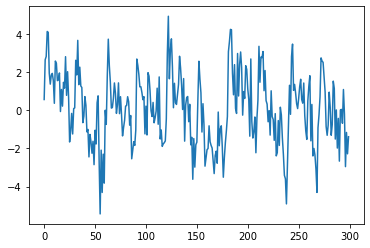

In [6]:
from wavelet_transform.test.synthetic_data import sound_wave, noise
from wavelet_transform.PCA.svd import SVD

sampling_rate = 60e6
fundamental = 2e6
harmonics = np.array([1/3,1/2,1,2,3])
amplitude = 1
duration = 10/fundamental
windows = 15
levels = 5
overlap = 0.1
wavelet = 'db10'
data,t = sound_wave(amplitude,fundamental*harmonics,0,duration,sampling_rate)
data += noise(1*amplitude,duration,sampling_rate)
plt.plot(data)
svd_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)
print(svd_object.stability_marker)
transform_object = wpt.dwpt(data,levels,wavelet)


### Harmonics

In [7]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import blackmanharris

transform energy 1289.687793091824
signal energy 4999.996057350658
transform energy 1289.6877933375633
signal energy 4999.996057350658


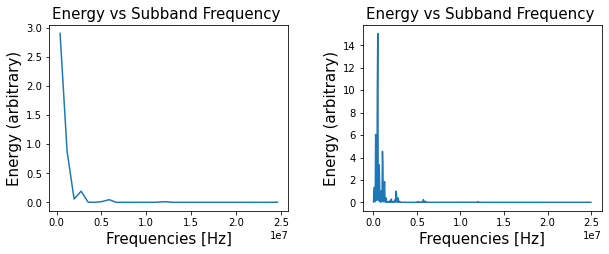

transform energy 644.7794057273873
signal energy 2499.984291580565
transform energy 644.7794058400239
signal energy 2499.984291580565


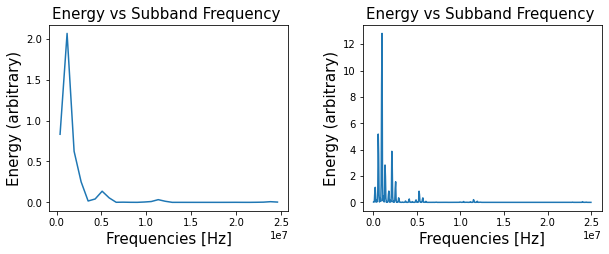

transform energy 322.32521204782967
signal energy 1249.938153340022
transform energy 322.3252120892764
signal energy 1249.938153340022


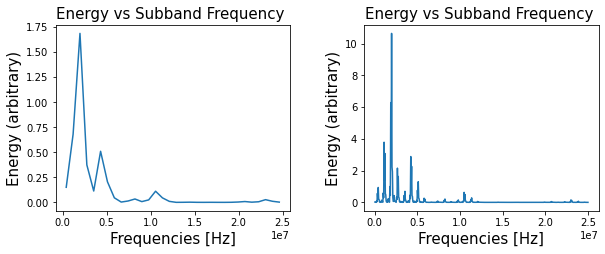

transform energy 214.88347470152212
signal energy 833.2732693915393
transform energy 214.88381928920168
signal energy 833.2732693915393


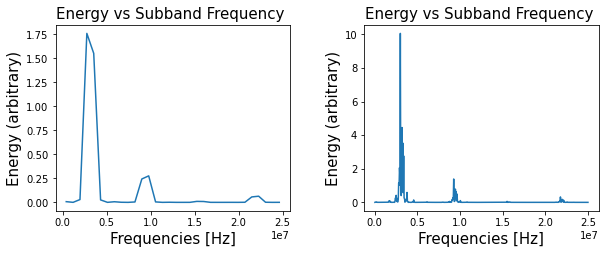

transform energy 107.44173737654829
signal energy 416.5973305591608
transform energy 107.44191375923184
signal energy 416.5973305591608


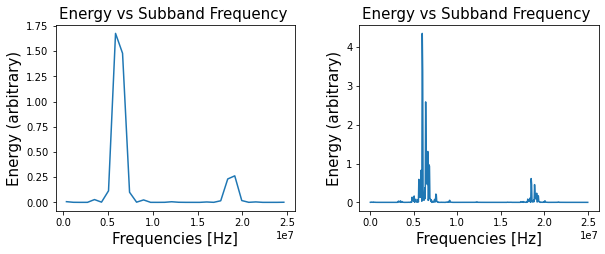

In [9]:

np.random.seed(2)

amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 100
gaussian_noise_std = amp_sin_waves*0.1 # set the standard devaition of the noise

test_frequencies = [0.5e6,1e6,2e6,3e6,6e6]
i = 0
for frequency in test_frequencies:
    if i == 10:
        harmonics = np.array([1/3,1/2,1,2,3])
        frequencies = frequency*harmonics # create list of frequencies for synthetic data
        i += 1
    else:
        frequencies = frequency

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period
    delay = None
    end = None

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, 0, signal_duration, 
        sampling_rate, delay, end
        )

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    # data += gaussian_noise

    # transform parameters
    levels = 4
    order = 1
    wavelet = f'db{order}'
    mode = 'symmetric'
    fig,ax = plt.subplots(1,2)
    i = 0
    for levels in [5,9]:
        # wpt
        transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet,mode)

        # plot frequencies
        plot.plot_energy_vs_freq(transform_object,sampling_rate,ax[i])
        i += 1

        # comparing energy of data and energy of the transformed data
        print('transform energy',transform_object.total_energy())
        print('signal energy',np.sum(data**2))
        # print('norm energy matrix',SVD_object.norm_energy_matrix)
    fig.tight_layout()
    fig.set_size_inches(9,3.5)
    plt.show()

### Energy distribution for a harmonic against daubechies order

1 highest energy node (488281.25, 537109.375)Hz, energy: 25.9291109505438
2 highest energy node (195312.5, 244140.625)Hz, energy: 18.2972085223019
3 highest energy node (1464843.75, 1513671.875)Hz, energy: 15.785420663133333
4 highest energy node (244140.625, 292968.75)Hz, energy: 15.044409239233492
5 highest energy node (1611328.125, 1660156.25)Hz, energy: 11.537779243098981
6 highest energy node (976562.5, 1025390.625)Hz, energy: 10.721718058041553
7 highest energy node (97656.25, 146484.375)Hz, energy: 10.389174824768212
8 highest energy node (927734.375, 976562.5)Hz, energy: 10.176898303386194
9 highest energy node (439453.125, 488281.25)Hz, energy: 10.145491736346367
10 highest energy node (292968.75, 341796.875)Hz, energy: 8.76000653173637
1 highest energy node (244140.625, 292968.75)Hz, energy: 30.738056150047257
2 highest energy node (488281.25, 537109.375)Hz, energy: 25.685528670383594
3 highest energy node (976562.5, 1025390.625)Hz, energy: 24.308539671233163
4 highest energy

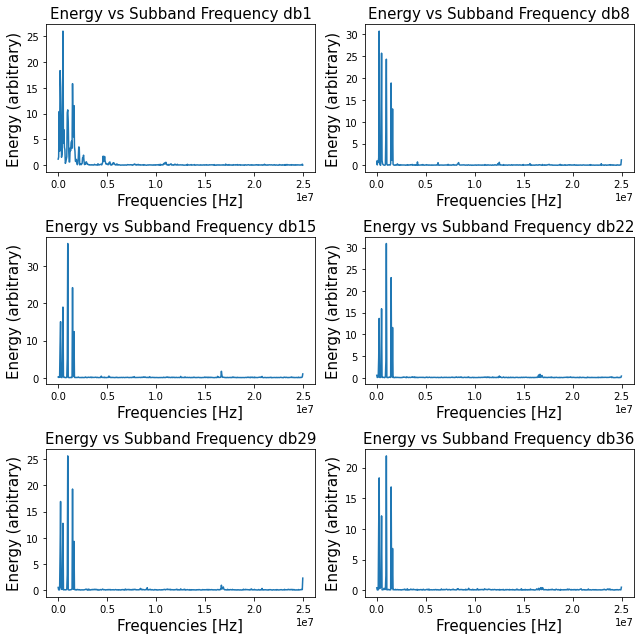

1 highest energy node (976562.5, 1025390.625)Hz, energy: 18.819307156279105
2 highest energy node (2978515.625, 3027343.75)Hz, energy: 11.366104434870545
3 highest energy node (537109.375, 585937.5)Hz, energy: 10.736690523082867
4 highest energy node (439453.125, 488281.25)Hz, energy: 10.476548355262267
5 highest energy node (3222656.25, 3271484.375)Hz, energy: 9.06900104077653
6 highest energy node (1953125.0, 2001953.125)Hz, energy: 7.493240277908872
7 highest energy node (244140.625, 292968.75)Hz, energy: 6.982829936393041
8 highest energy node (927734.375, 976562.5)Hz, energy: 6.951114412382082
9 highest energy node (1855468.75, 1904296.875)Hz, energy: 6.736114343332688
10 highest energy node (3027343.75, 3076171.875)Hz, energy: 6.3290121035652085
1 highest energy node (976562.5, 1025390.625)Hz, energy: 27.80544346420062
2 highest energy node (488281.25, 537109.375)Hz, energy: 18.90227408415356
3 highest energy node (2001953.125, 2050781.25)Hz, energy: 14.314711936629378
4 highest 

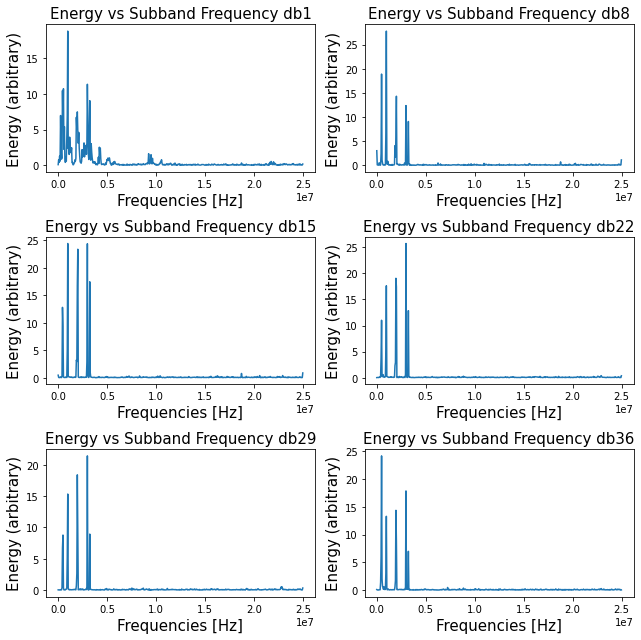

1 highest energy node (1953125.0, 2001953.125)Hz, energy: 15.50478520159966
2 highest energy node (6494140.625, 6542968.75)Hz, energy: 7.953614538061059
3 highest energy node (927734.375, 976562.5)Hz, energy: 7.926404525532206
4 highest energy node (1074218.75, 1123046.875)Hz, energy: 7.589757372327755
5 highest energy node (6005859.375, 6054687.5)Hz, energy: 6.857211031522116
6 highest energy node (976562.5, 1025390.625)Hz, energy: 6.443047735211536
7 highest energy node (878906.25, 927734.375)Hz, energy: 4.767649890893543
8 highest energy node (1855468.75, 1904296.875)Hz, energy: 4.695000276379265
9 highest energy node (4199218.75, 4248046.875)Hz, energy: 3.9993156515715462
10 highest energy node (5957031.25, 6005859.375)Hz, energy: 3.6061159177692006
1 highest energy node (2001953.125, 2050781.25)Hz, energy: 17.801994685919308
2 highest energy node (1953125.0, 2001953.125)Hz, energy: 16.94754652242636
3 highest energy node (4003906.25, 4052734.375)Hz, energy: 12.106802260990625
4 hi

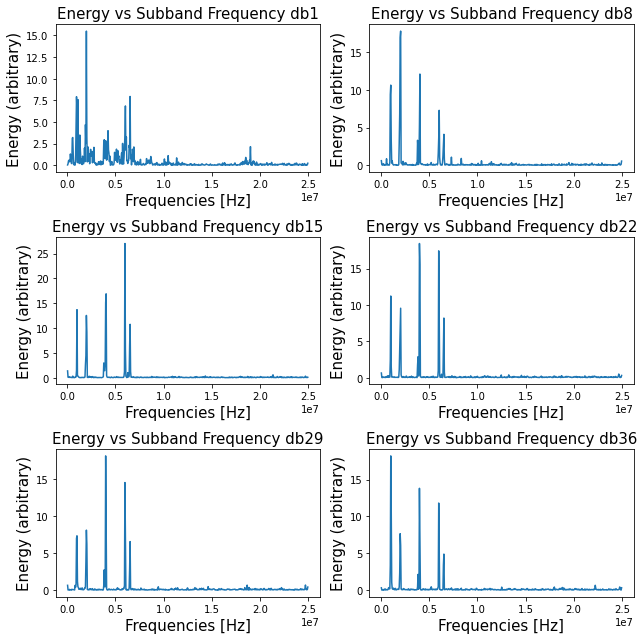

1 highest energy node (1611328.125, 1660156.25)Hz, energy: 10.886790791670805
2 highest energy node (1513671.875, 1562500.0)Hz, energy: 10.008669029721515
3 highest energy node (2978515.625, 3027343.75)Hz, energy: 8.886827533791944
4 highest energy node (3271484.375, 3320312.5)Hz, energy: 5.905674007051979
5 highest energy node (3369140.625, 3417968.75)Hz, energy: 5.315159314992135
6 highest energy node (8984375.0, 9033203.125)Hz, energy: 4.935292166759402
7 highest energy node (6445312.5, 6494140.625)Hz, energy: 4.907852763570829
8 highest energy node (6494140.625, 6542968.75)Hz, energy: 4.704242786708993
9 highest energy node (2880859.375, 2929687.5)Hz, energy: 4.245494248012984
10 highest energy node (1416015.625, 1464843.75)Hz, energy: 4.173882943923442
1 highest energy node (8984375.0, 9033203.125)Hz, energy: 14.63059397502417
2 highest energy node (6005859.375, 6054687.5)Hz, energy: 13.880525525231503
3 highest energy node (2978515.625, 3027343.75)Hz, energy: 11.5155328388053
4 h

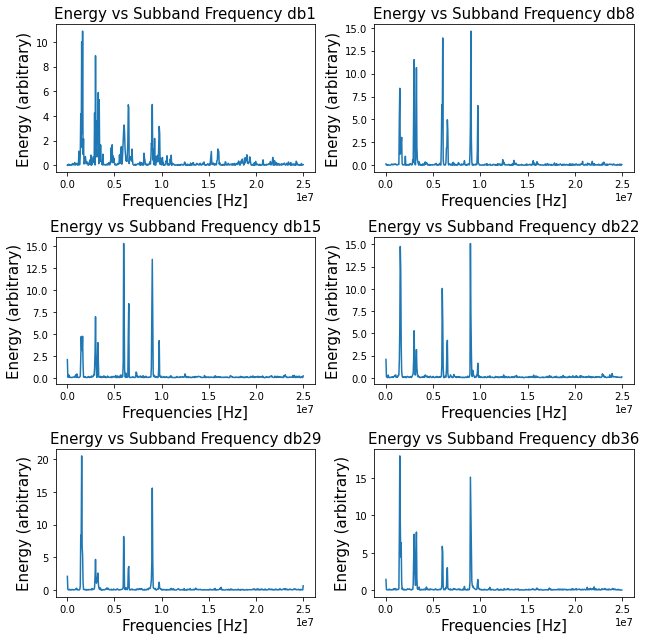

1 highest energy node (3906250.0, 3955078.125)Hz, energy: 8.90389830031383
2 highest energy node (1855468.75, 1904296.875)Hz, energy: 6.122726092538206
3 highest energy node (13037109.375, 13085937.5)Hz, energy: 5.841598336878069
4 highest energy node (12060546.875, 12109375.0)Hz, energy: 5.523672638392199
5 highest energy node (2148437.5, 2197265.625)Hz, energy: 3.7449296855752574
6 highest energy node (7666015.625, 7714843.75)Hz, energy: 3.471165899098011
7 highest energy node (1074218.75, 1123046.875)Hz, energy: 3.4222681860849375
8 highest energy node (11962890.625, 12011718.75)Hz, energy: 3.1118546528314606
9 highest energy node (1953125.0, 2001953.125)Hz, energy: 3.0521541070162144
10 highest energy node (12841796.875, 12890625.0)Hz, energy: 2.3782944907925074
1 highest energy node (4003906.25, 4052734.375)Hz, energy: 12.66840030795094
2 highest energy node (2001953.125, 2050781.25)Hz, energy: 10.657633991336287
3 highest energy node (8007812.5, 8056640.625)Hz, energy: 10.4612701

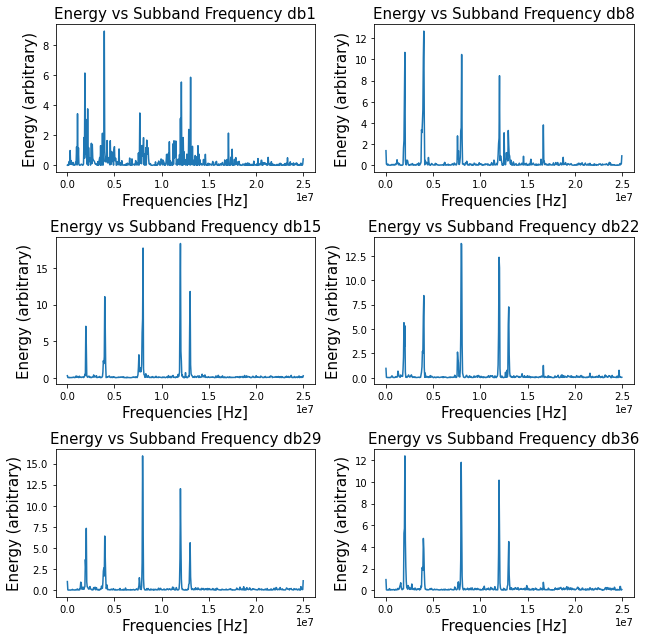

1 highest energy node (2441406.25, 2490234.375)Hz, energy: 4.265884080706957
2 highest energy node (14990234.375, 15039062.5)Hz, energy: 4.254727618556928
3 highest energy node (2587890.625, 2636718.75)Hz, energy: 3.387449899949647
4 highest energy node (3710937.5, 3759765.625)Hz, energy: 3.343374710514064
5 highest energy node (2539062.5, 2587890.625)Hz, energy: 3.335969670958338
6 highest energy node (2148437.5, 2197265.625)Hz, energy: 3.0660052507220312
7 highest energy node (14941406.25, 14990234.375)Hz, energy: 2.3778158935285125
8 highest energy node (2197265.625, 2246093.75)Hz, energy: 2.234803106250494
9 highest energy node (9960937.5, 10009765.625)Hz, energy: 2.1264443755071145
10 highest energy node (5029296.875, 5078125.0)Hz, energy: 2.118962922769989
1 highest energy node (14941406.25, 14990234.375)Hz, energy: 13.23527679242471
2 highest energy node (2441406.25, 2490234.375)Hz, energy: 12.41025259123494
3 highest energy node (10009765.625, 10058593.75)Hz, energy: 9.83164941

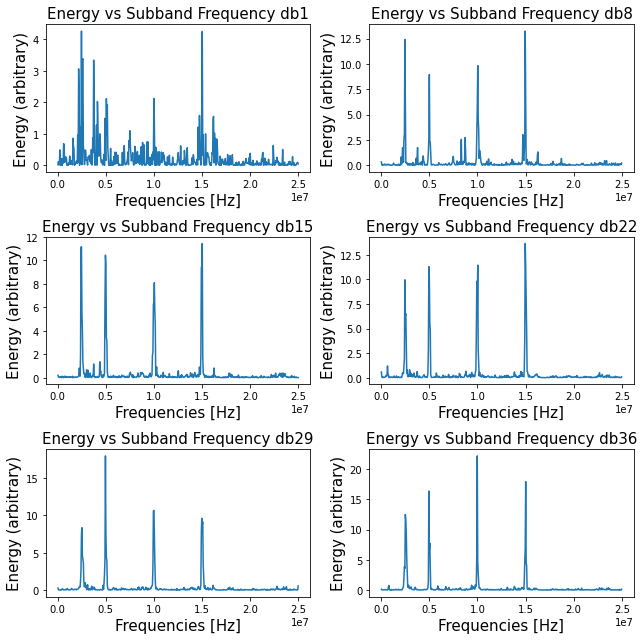

1 highest energy node (3027343.75, 3076171.875)Hz, energy: 4.549644478428712
2 highest energy node (17919921.875, 17968750.0)Hz, energy: 3.9255838469799134
3 highest energy node (19482421.875, 19531250.0)Hz, energy: 3.4139337357122406
4 highest energy node (5957031.25, 6005859.375)Hz, energy: 3.2359235414815974
5 highest energy node (3222656.25, 3271484.375)Hz, energy: 3.2011562481007867
6 highest energy node (3271484.375, 3320312.5)Hz, energy: 3.119472376866662
7 highest energy node (2880859.375, 2929687.5)Hz, energy: 2.3294037178328293
8 highest energy node (6738281.25, 6787109.375)Hz, energy: 2.3056510035821662
9 highest energy node (12988281.25, 13037109.375)Hz, energy: 2.1572561972430093
10 highest energy node (12011718.75, 12060546.875)Hz, energy: 1.936530503935909
1 highest energy node (17919921.875, 17968750.0)Hz, energy: 10.728199911529124
2 highest energy node (5957031.25, 6005859.375)Hz, energy: 9.647403784509384
3 highest energy node (12060546.875, 12109375.0)Hz, energy: 8.

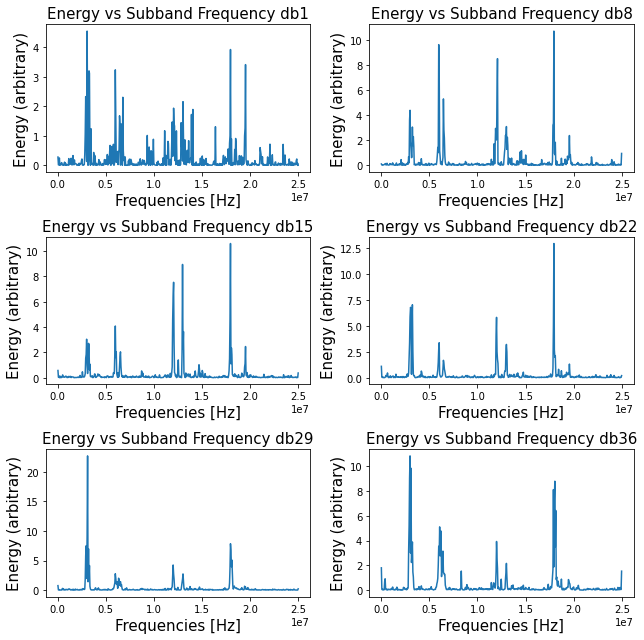

In [11]:
amp_sin_waves = 1 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 80
gaussian_noise_std = amp_sin_waves*0.3 # set the standard devaition of the noise

test_frequencies = [0.5e6,1e6,2e6,3e6,4e6,5e6,6e6]
test_harmonics = True
for frequency in test_frequencies:
    if test_harmonics: # adjust to enable harmonics
        harmonics = np.array([1/2,1,2,3])
        frequencies = frequency*harmonics # create list of frequencies for synthetic data
    else:
        frequencies = frequency

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, 0, signal_duration, 
        sampling_rate, delay, end
        )
    data = data*blackmanharris(len(data))

    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 9
    order = 1
    mode = 'symmetric'
    fig,ax = plt.subplots(3,2)
    u = 0
    col = 0
    for order in range(1,39,7):
        row = int(u)
        wavelet = f'db{order}'
        # wpt
        transform_object = wpt.dwpt(data,levels,wavelet,mode)

        # plot frequencies
        plot.plot_energy_vs_freq(transform_object,sampling_rate,ax[row,col],wavelet)
        u += 0.5
        if col == 0:
            col = 1
        elif col == 1:
            col = 0

        # comparing energy of data and energy of the transformed data
        # print('transform energy',transform_object.total_energy())
        # print('signal energy',np.sum(data**2))
        
        nodes = transform_object.get_level().copy()
        nodes.sort(key=lambda x:x.energy)
        top_i_nodes = 10
        for i in range(1,top_i_nodes+1):
            print(f'{i} highest energy node {nodes[-i].frequency_range}Hz, energy: {nodes[-i].energy}')
    
    fig.set_size_inches(9,9)
    fig.tight_layout()
    plt.show()

### inverse above transform

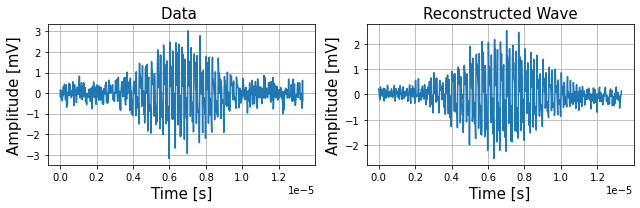

In [13]:
dwpt_inverse = inv.inv_dwpt(transform_object, min_energy=1)

fig,ax = plt.subplots(1,2)
plot.plot_wave(data,t_plot,ax[0])
ax[1].plot(t_plot,dwpt_inverse)
ax[1].set_title('Reconstructed Wave',fontsize=15)
ax[1].set_xlabel('Time [s]',fontsize=15)
ax[1].set_ylabel('Amplitude [mV]',fontsize=15)
ax[1].grid(True)
fig.set_size_inches(9,3)
fig.tight_layout()
plt.show()

### PCA windowing testing

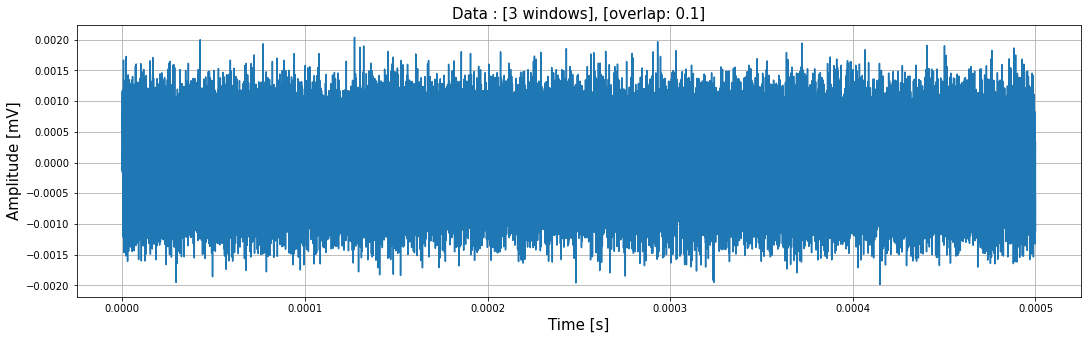

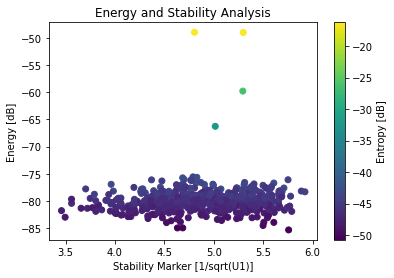

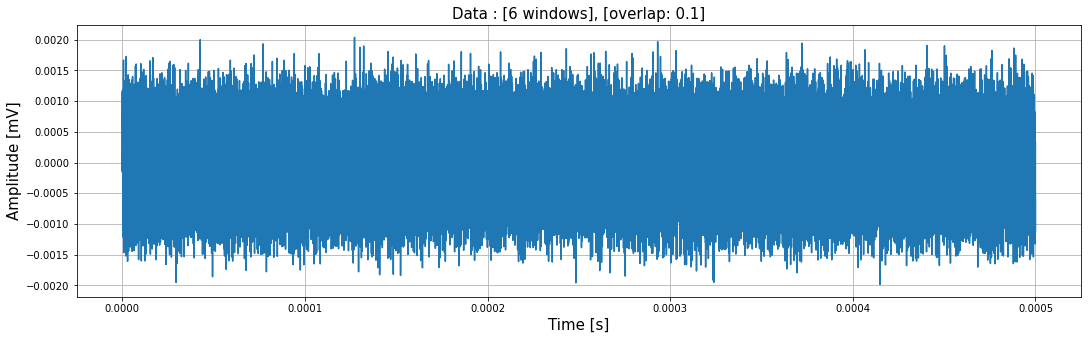

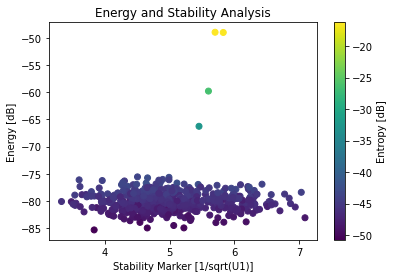

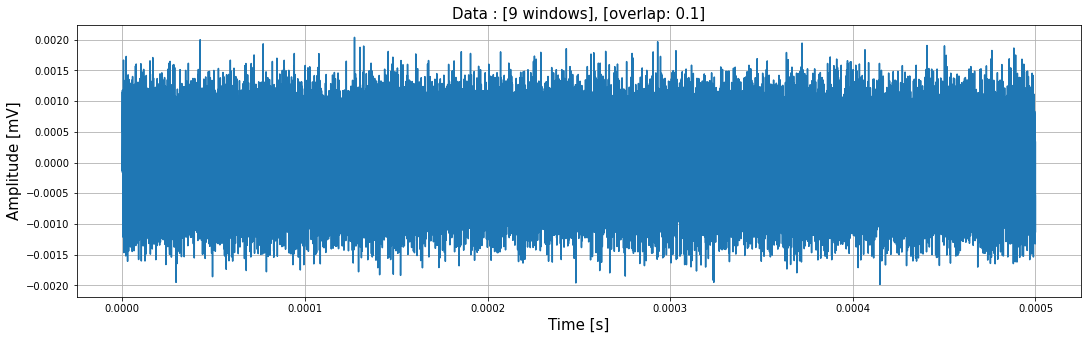

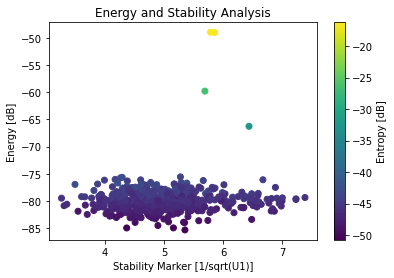

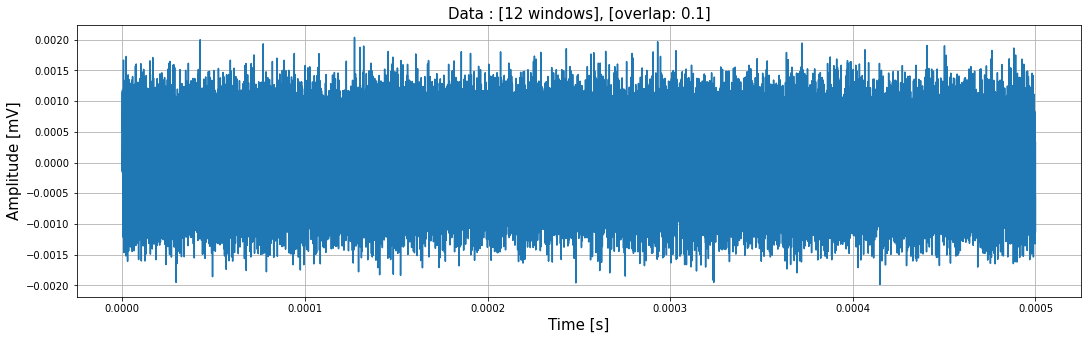

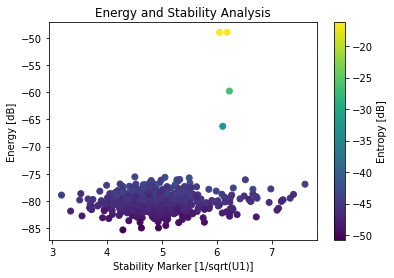

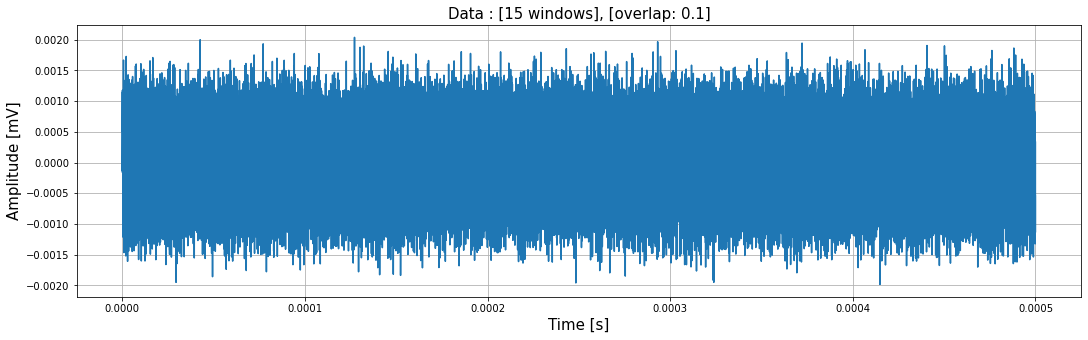

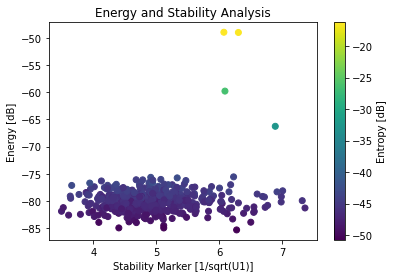

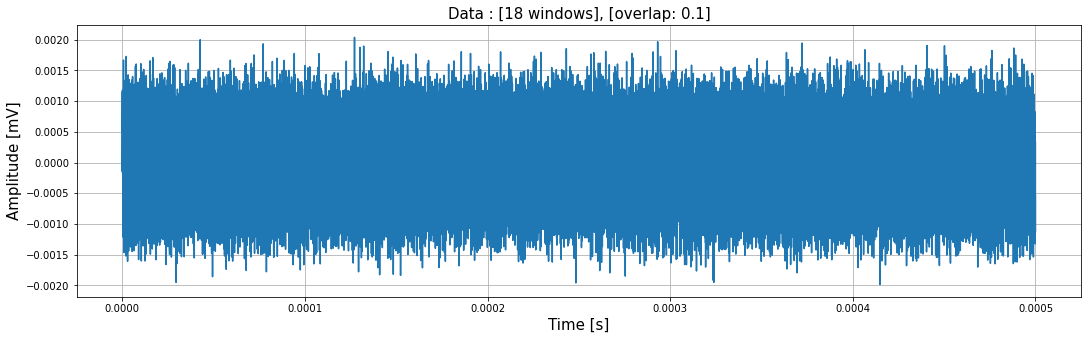

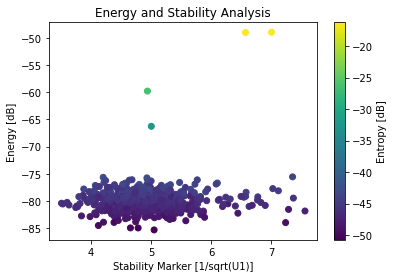

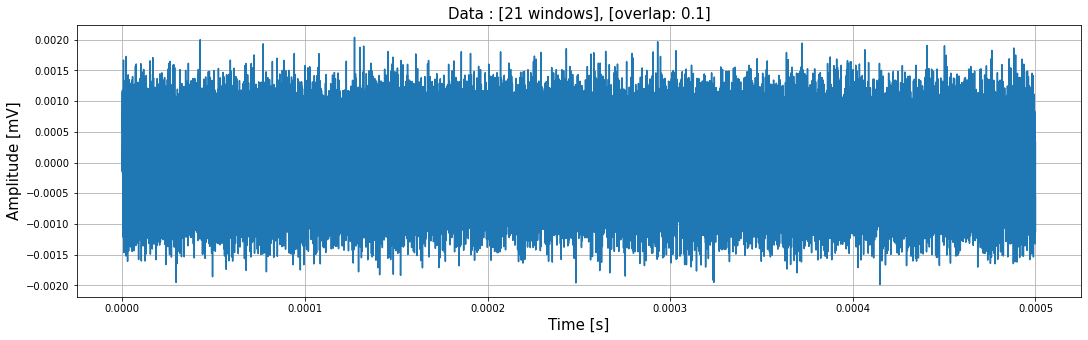

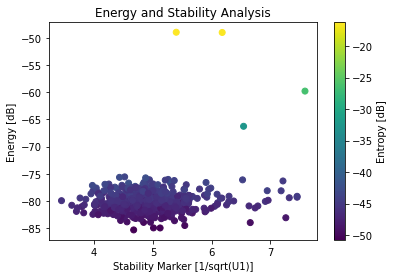

KeyboardInterrupt: 

In [16]:
import sys
sys.path.append('..')

from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import blackmanharris
np.random.seed(2)

amp_sin_waves = 0.001 # amplitude of the sine waves added together to form the signal
sampling_rate = 50e6 
no_time_periods = 1000
gaussian_noise_std = amp_sin_waves*0.3 # set the standard devaition of the noise

test_frequencies = [2e6]
test_harmonics = False

for frequency in test_frequencies:
    frequencies = frequency

    time_period = 1/frequency
    signal_duration = no_time_periods*time_period

    # generate data
    data, t_plot = sd.sound_wave(
        amp_sin_waves, frequencies, 0, signal_duration, 
        sampling_rate
        )

    if test_harmonics:
        harmonics = np.array([1/2,2,3])
        h_freq = frequency*harmonics # create list of frequencies for synthetic data
        harmonics, t_plot = sd.sound_wave(amp_sin_waves/4,h_freq,signal_duration,sampling_rate)
        data += harmonics
    # add noise
    gaussian_noise = sd.noise(gaussian_noise_std,signal_duration,sampling_rate)
    data += gaussian_noise

    # transform parameters
    levels = 9
    db_order = 38
    wavelet = f'db{db_order}'
    mode = 'symmetric'

    # create SVD object which windows, transforms, and performs SVD
    for windows in range(3,30,3):
        overlap = 0.1
        SVD_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)

        # important parameters
        win_data_shape = SVD_object.windowed_data.shape

        # create plots to show windowed data
        win_len = SVD_object.windowed_data.shape[1]
        fig1,ax1 = plt.subplots()
        fig1.set_size_inches(18,5)
        plot.plot_wave(data,t_plot,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
        blackman_window = np.blackman(win_len)
        zeros = np.zeros(data.shape)
        offset = 0

        plot_windows = False
        if plot_windows:
            print('plotting windows')
            for _ in range(windows): # plot windows
                time_plot = t_plot[offset:offset+win_len]
                ax1.plot(time_plot,blackman_window)
                offset += SVD_object.offset
        plt.show()
        # wpt
        transform_object = wpt.dwpt(data*blackmanharris(len(data)),levels,wavelet,mode)

        # some useful functions
        def compute_shannon_entropy(data):
            '''
            Calculates the shannon entropy of an array.
            Same implementation as the matlab function wentropy.
            '''
            return -np.sum(data**2*np.log(data**2)) 
        
        # plot energy, entropy, and stability
        stability_markers = SVD_object.stability_marker

        energy = list(transform_object.info()["energy"])
        log_energy = 10*np.log10(energy)

        entropy = []
        for node in transform_object.get_level(): # final level nodes
            reconstructed_wave = inv.inv_dwpt(transform_object, nodes=node)
            entropy.append(compute_shannon_entropy(reconstructed_wave))
        
        entropy = 10*np.log10(entropy)
        fig2,ax2 = plt.subplots()
        im = ax2.scatter(stability_markers,log_energy,c=entropy)
        ax2.set_xlabel('Stability Marker [1/sqrt(U1)]')
        ax2.set_ylabel('Energy [dB]')
        ax2.set_title('Energy and Stability Analysis')
        fig2.colorbar(im,ax=ax2,label='Entropy [dB]')
        plt.show()

### Real data

In [2]:
import sys
sys.path.append('..')

from wavelet_transform.postprocess import plotting as plot
from wavelet_transform.PCA.svd import SVD
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.wpt import inverse_transform as inv

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import blackmanharris

25002
1500


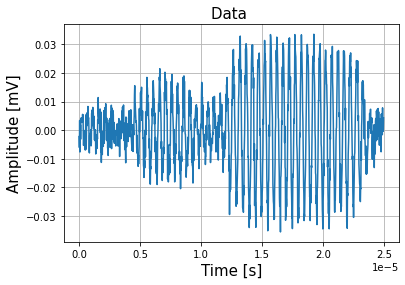

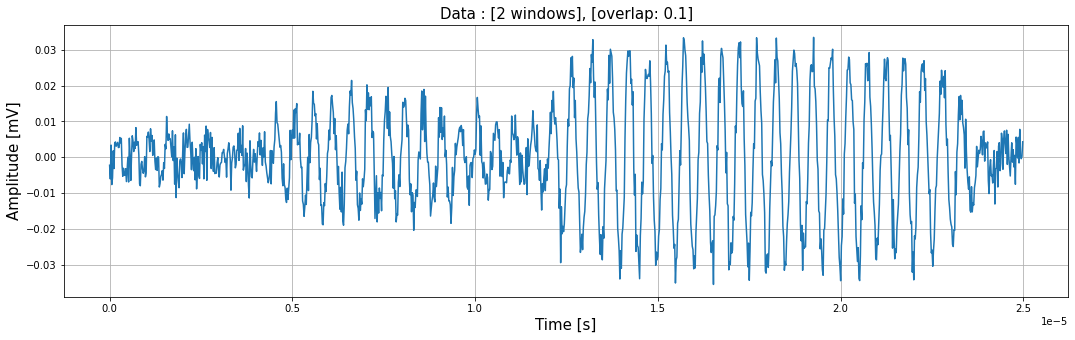

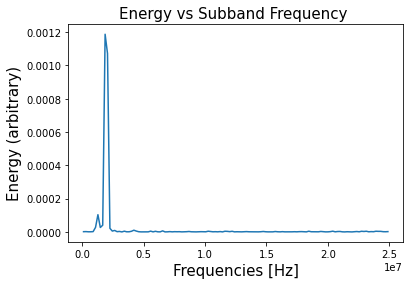

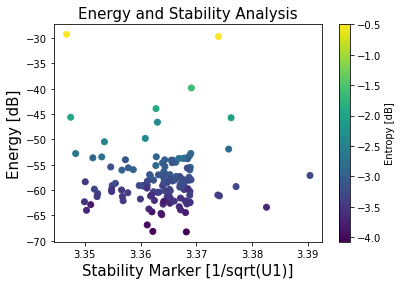

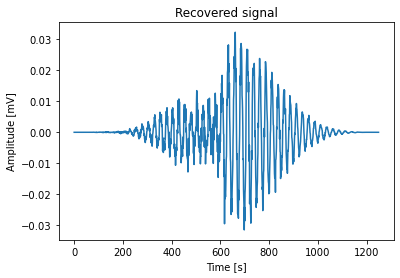

energy rec 6.271046443836968e-05


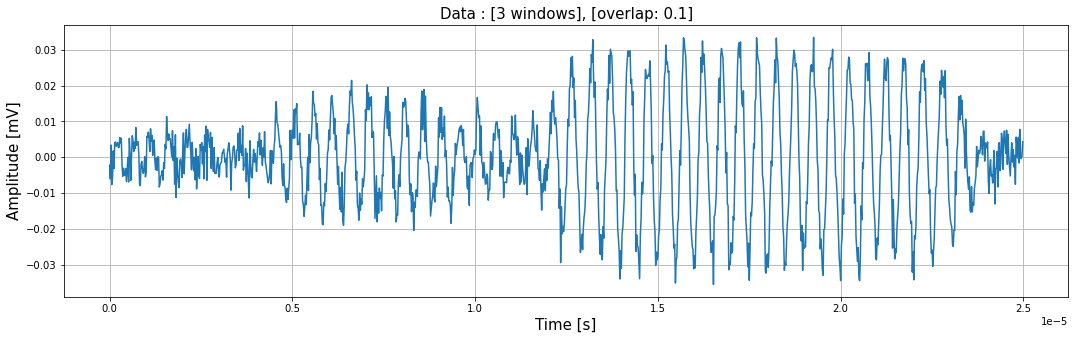

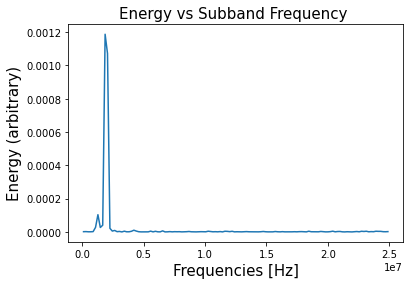

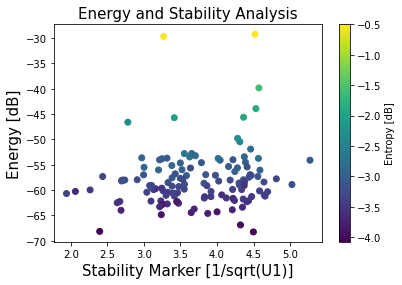

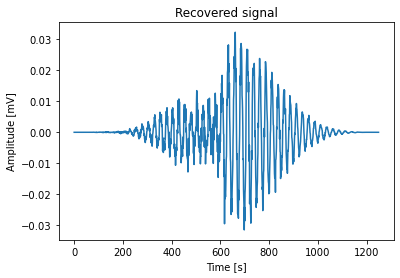

energy rec 6.271046443836968e-05


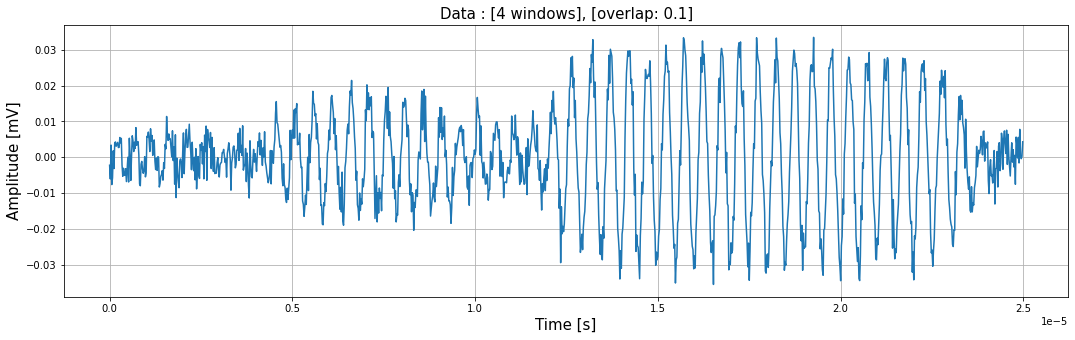

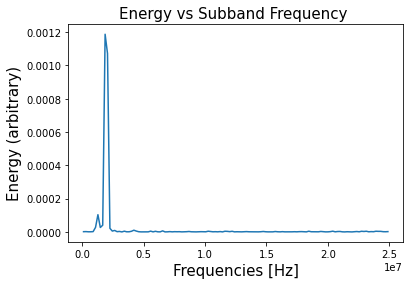

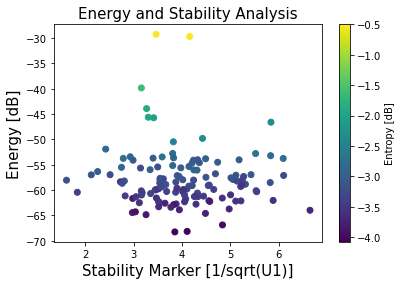

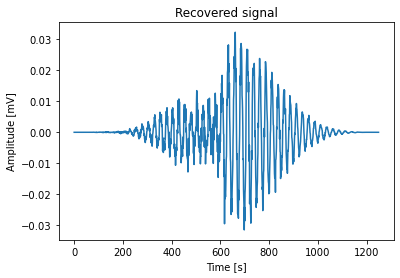

energy rec 6.271046443836968e-05


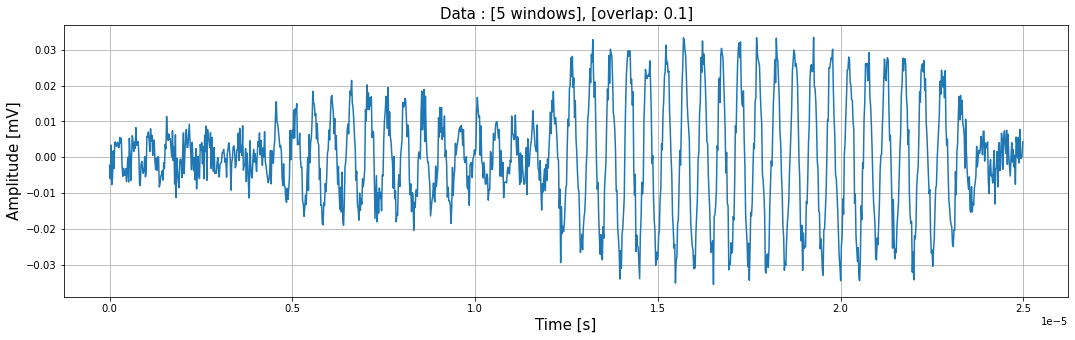

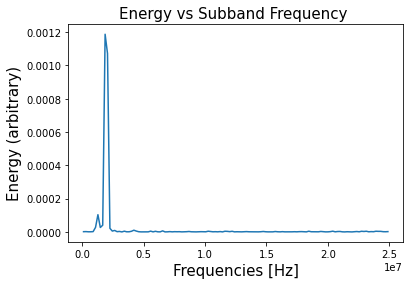

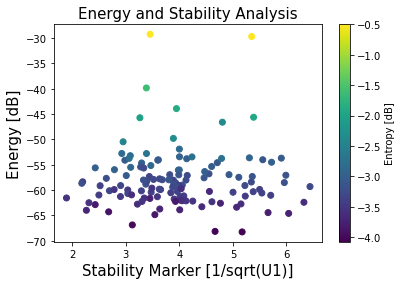

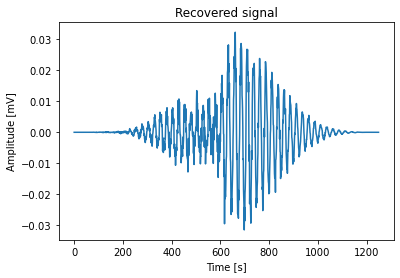

energy rec 6.271046443836968e-05


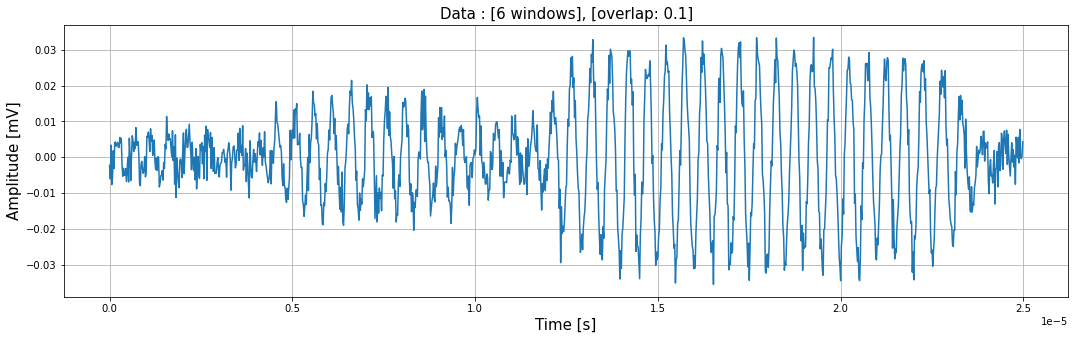

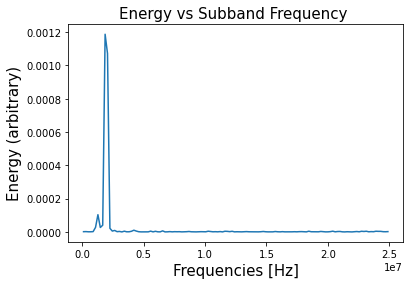

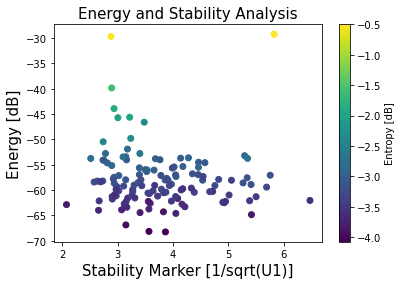

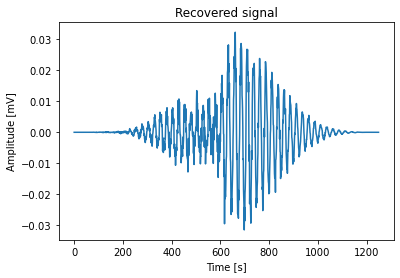

energy rec 6.271046443836968e-05


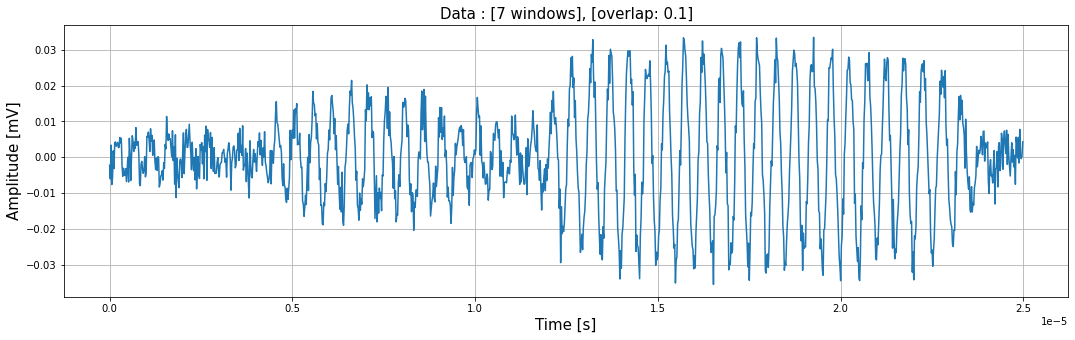

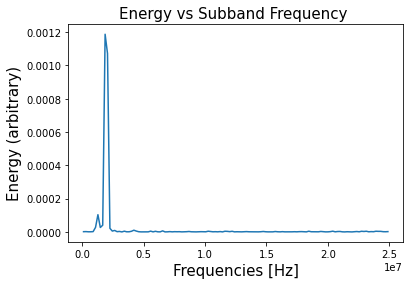

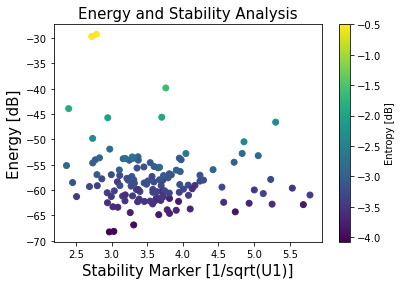

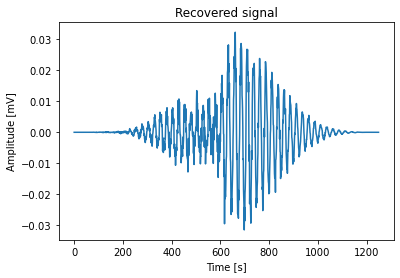

energy rec 6.271046443836968e-05


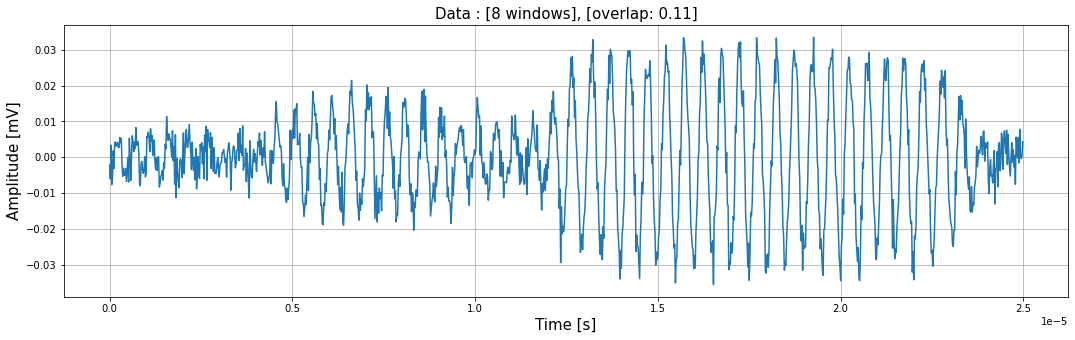

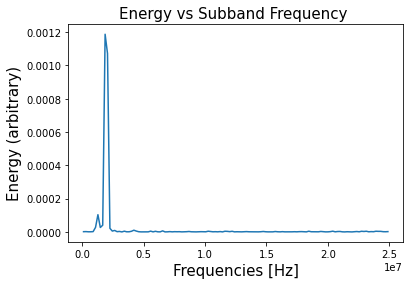

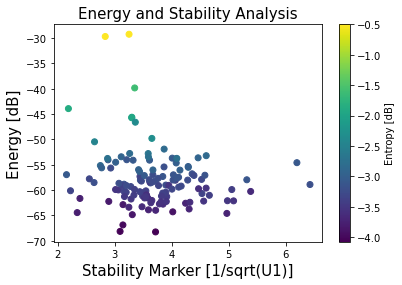

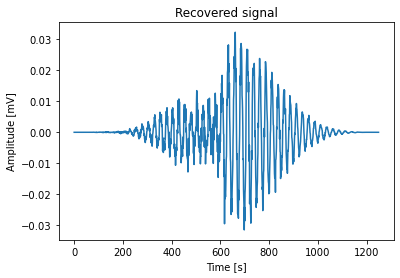

energy rec 6.271046443836968e-05


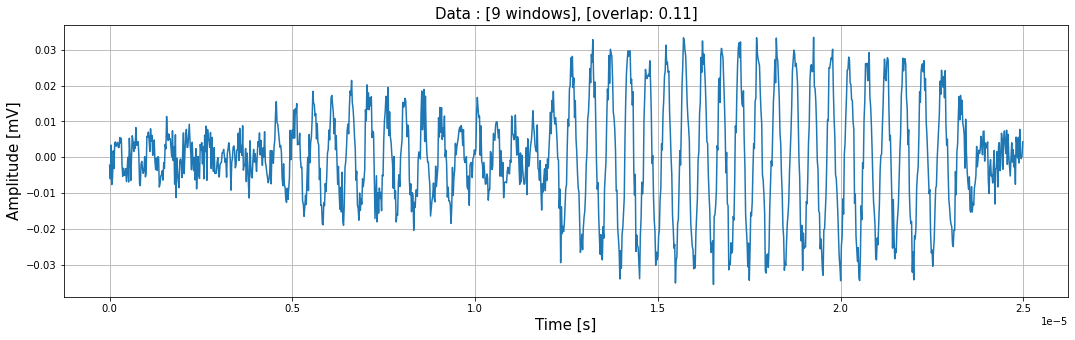

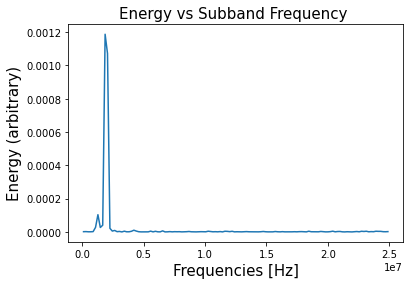

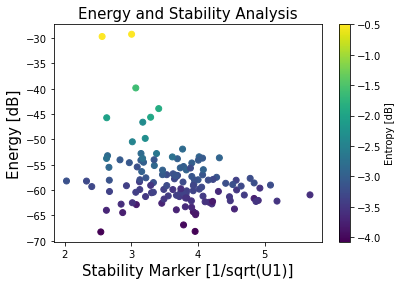

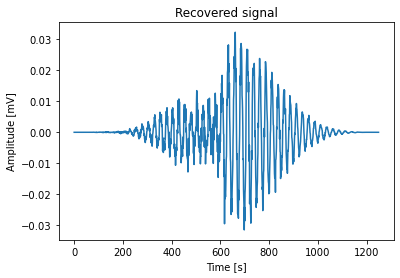

energy rec 6.271046443836968e-05


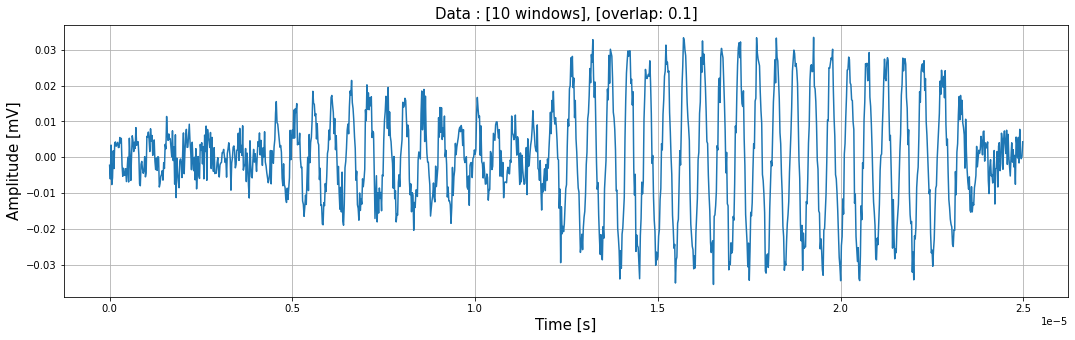

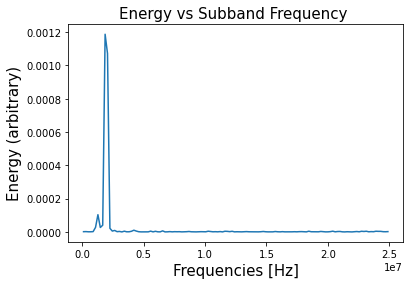

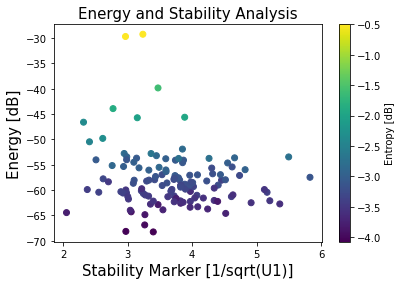

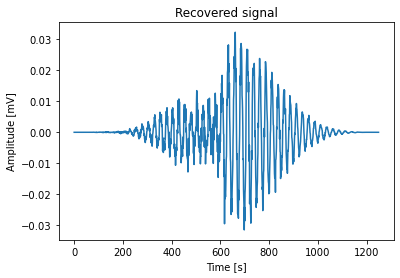

energy rec 6.271046443836968e-05


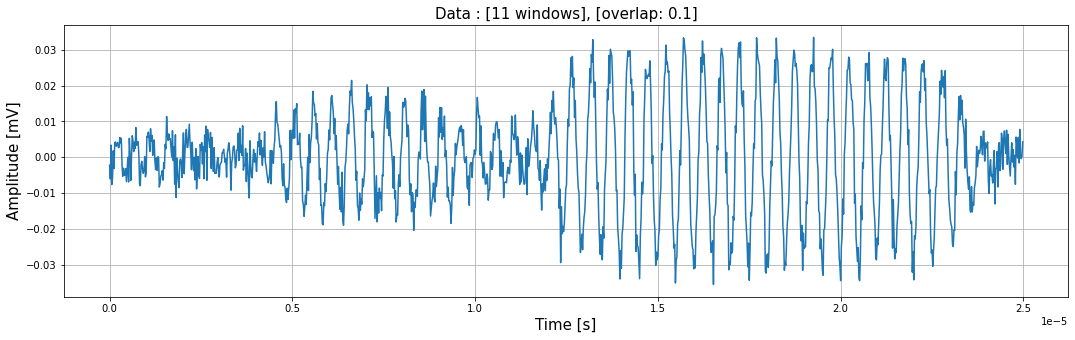

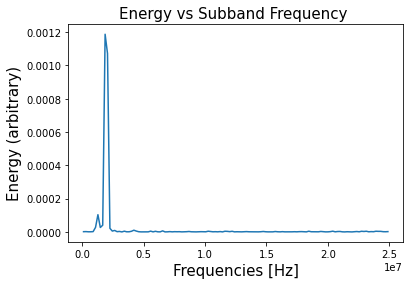

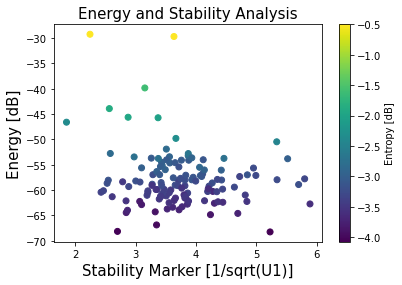

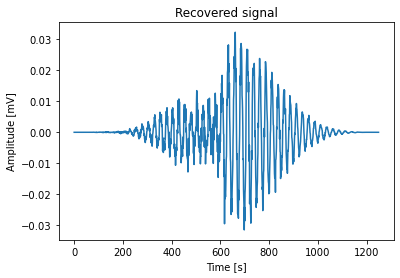

energy rec 6.271046443836968e-05


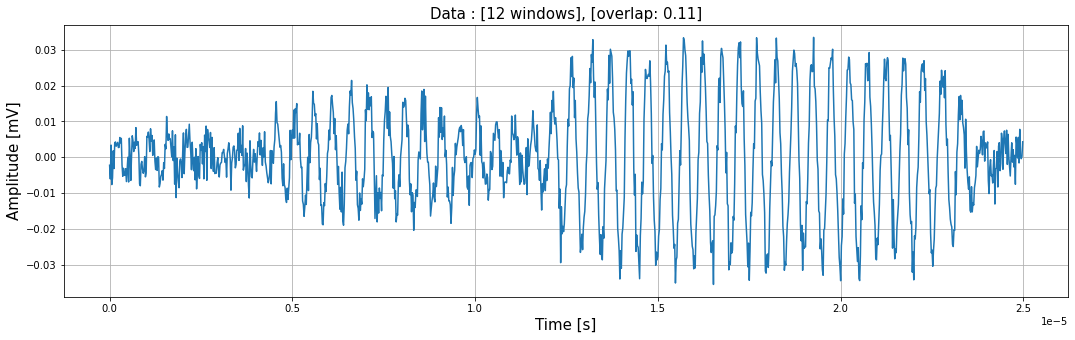

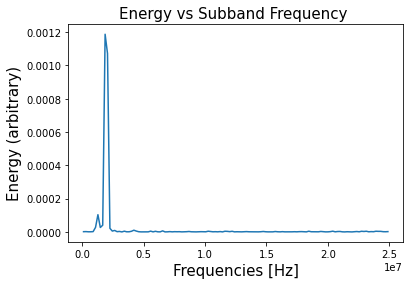

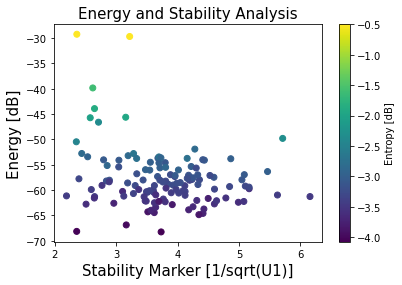

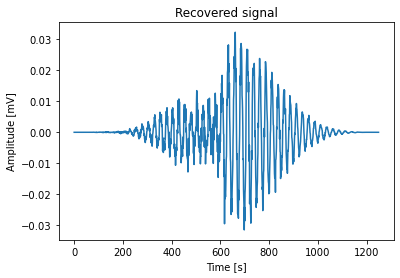

energy rec 6.271046443836968e-05


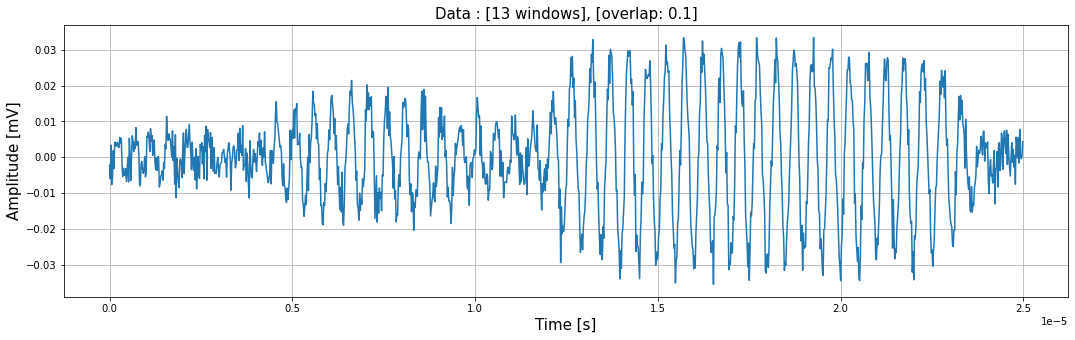

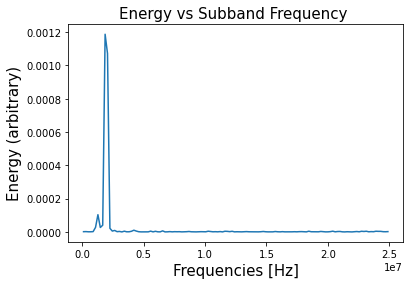

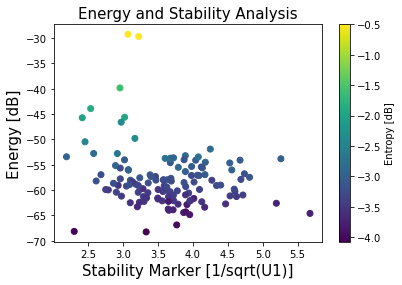

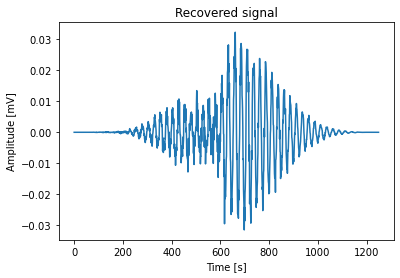

energy rec 6.271046443836968e-05


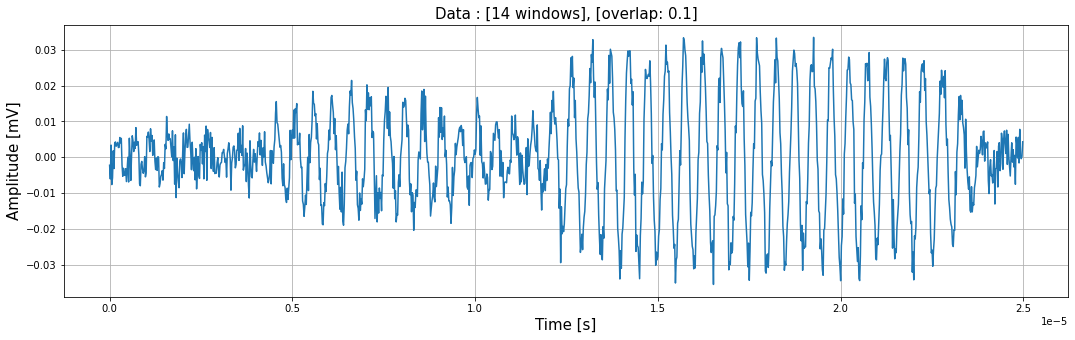

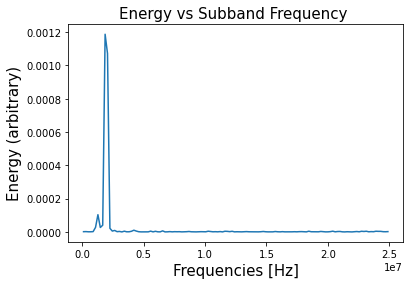

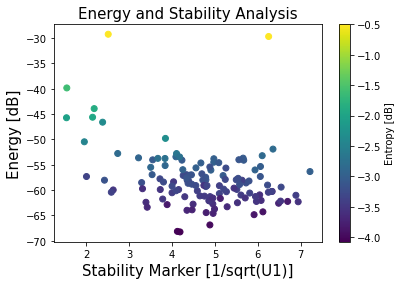

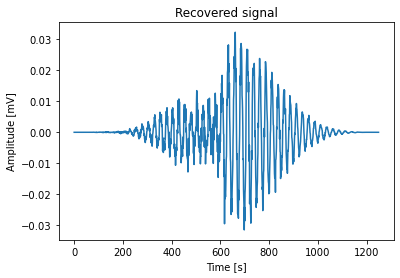

energy rec 6.271046443836968e-05
25002
1510


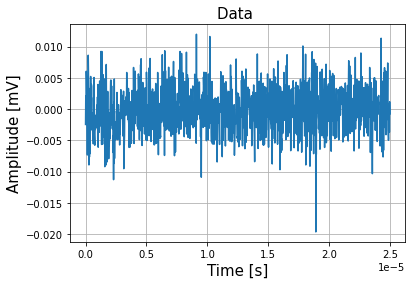

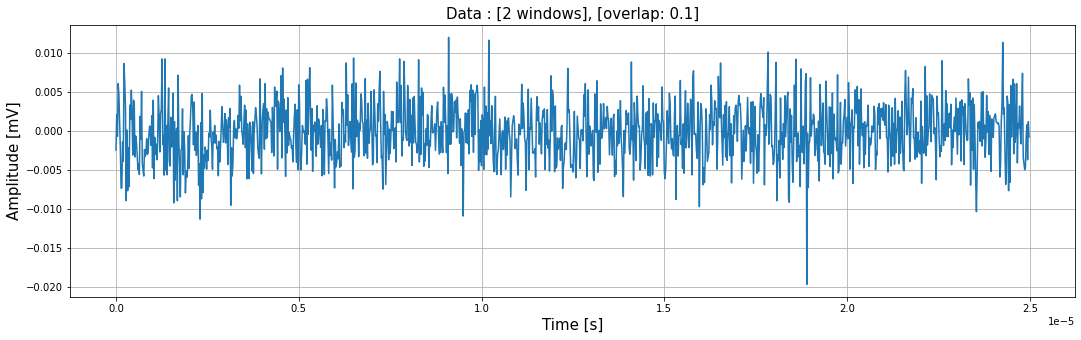

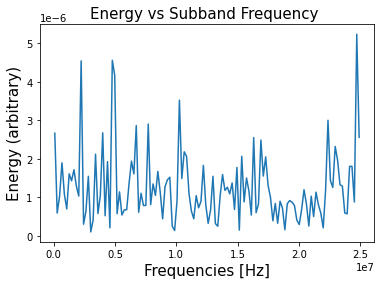

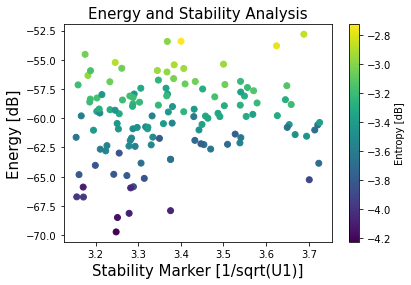

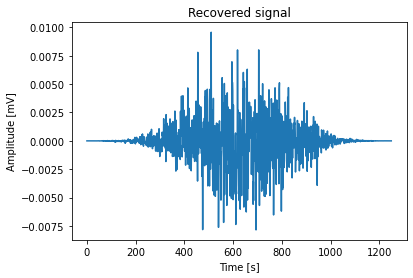

energy rec 3.080844084639521e-06


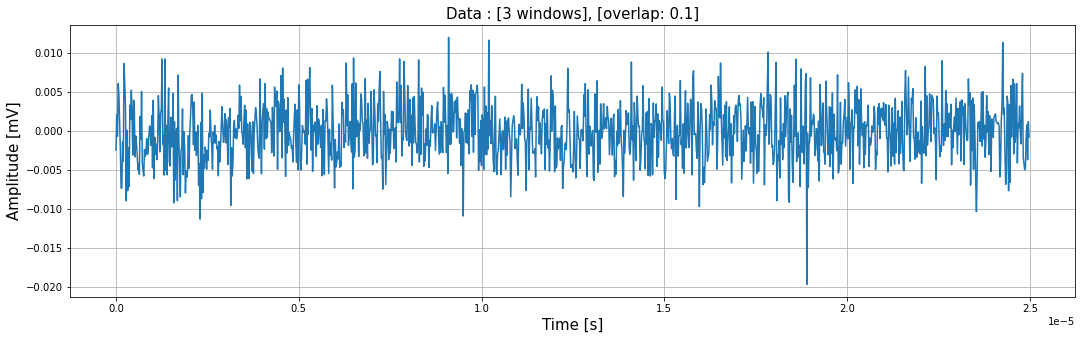

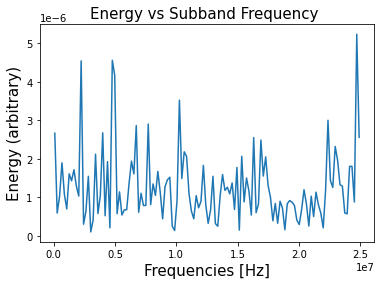

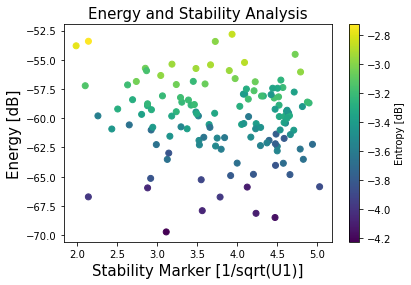

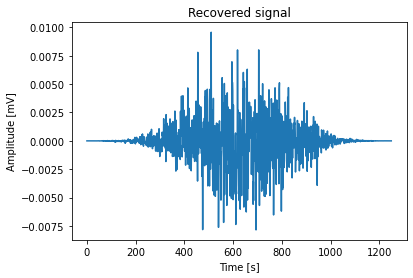

energy rec 3.080844084639521e-06


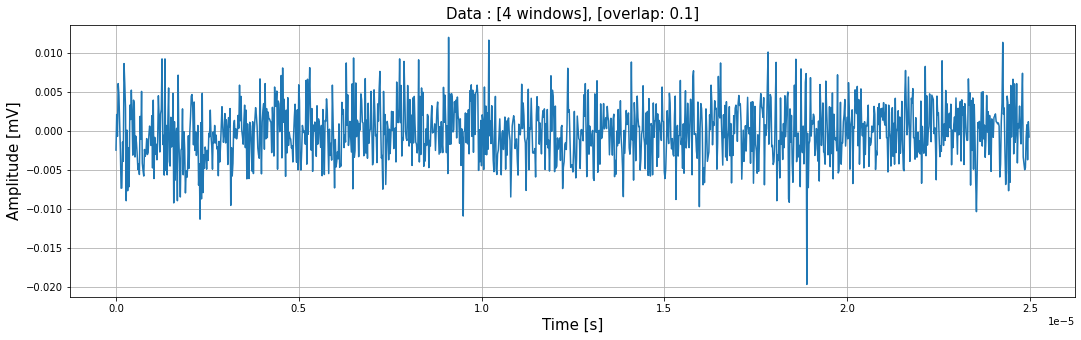

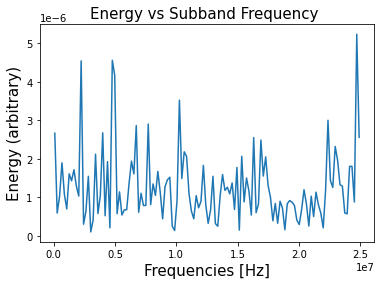

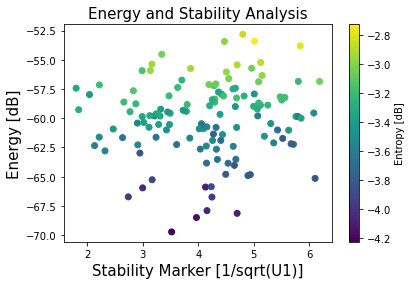

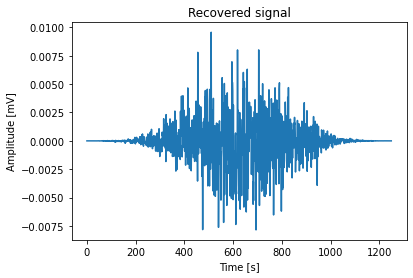

energy rec 3.080844084639521e-06


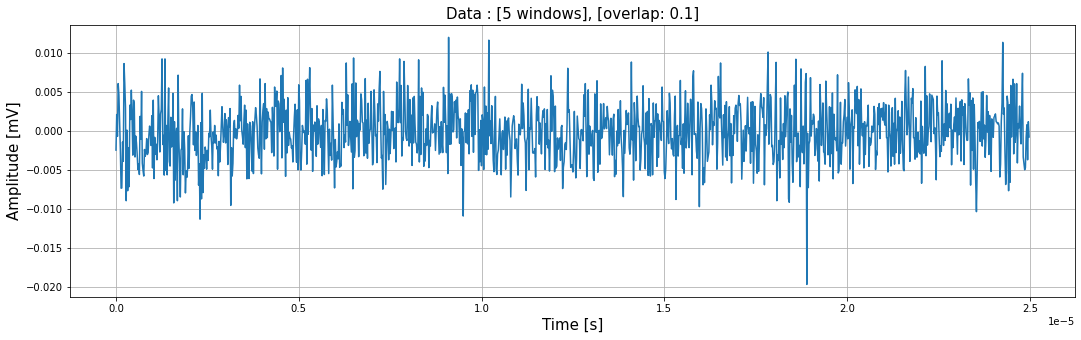

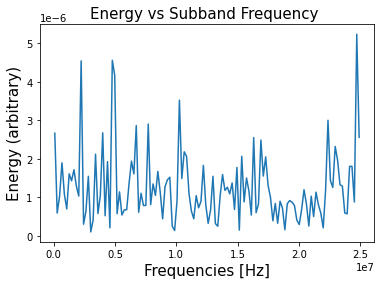

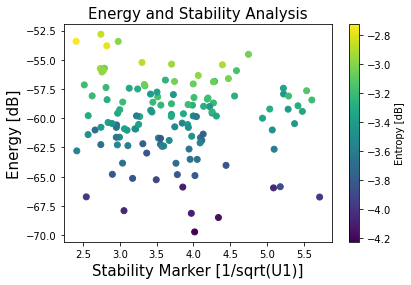

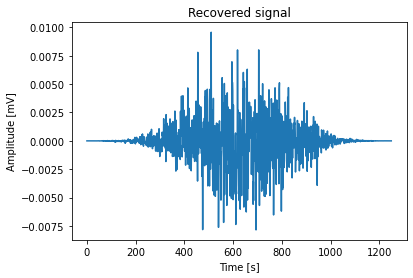

energy rec 3.080844084639521e-06


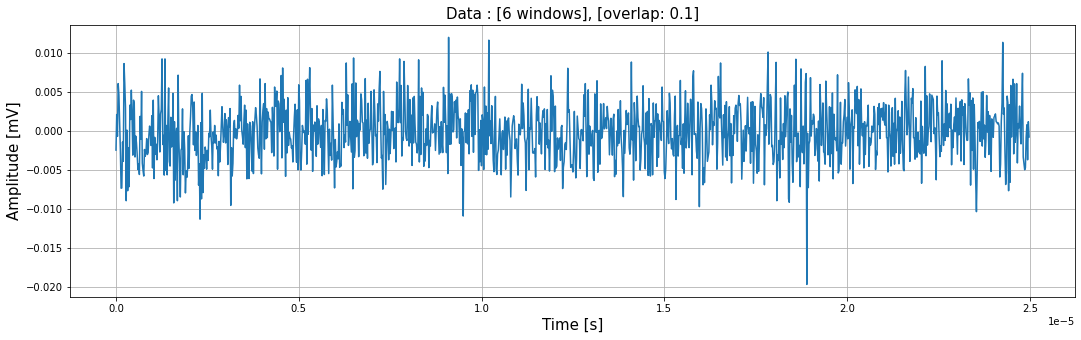

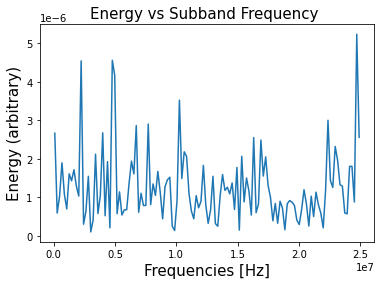

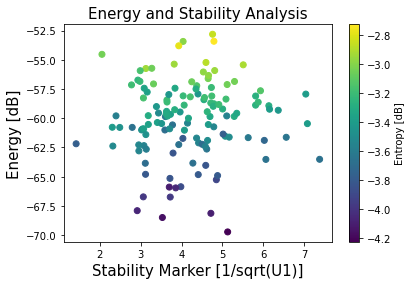

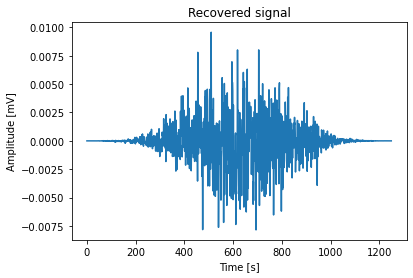

energy rec 3.080844084639521e-06


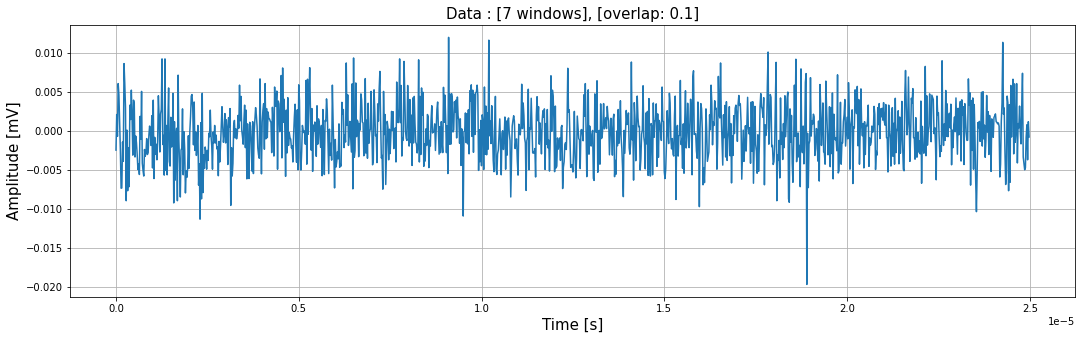

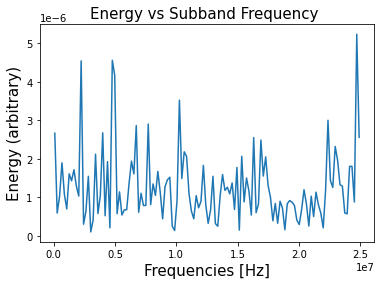

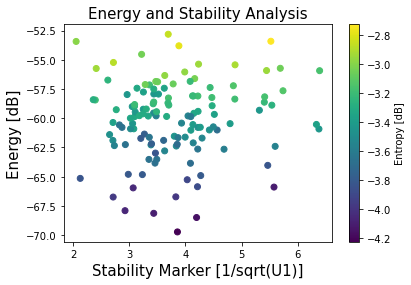

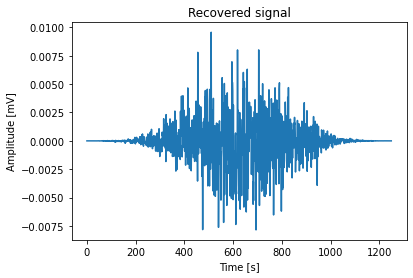

energy rec 3.080844084639521e-06


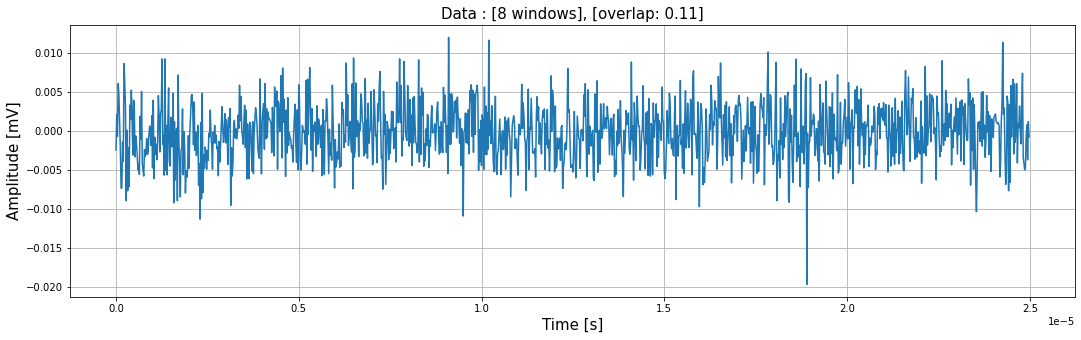

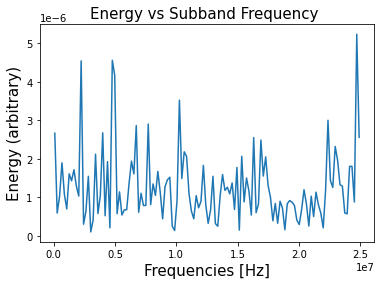

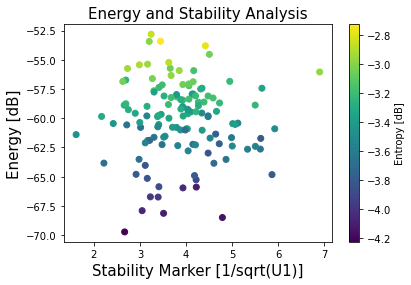

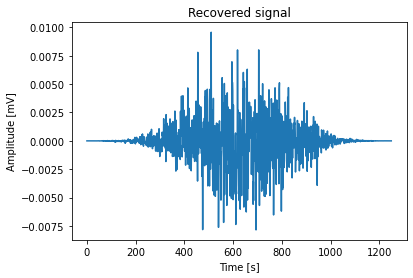

energy rec 3.080844084639521e-06


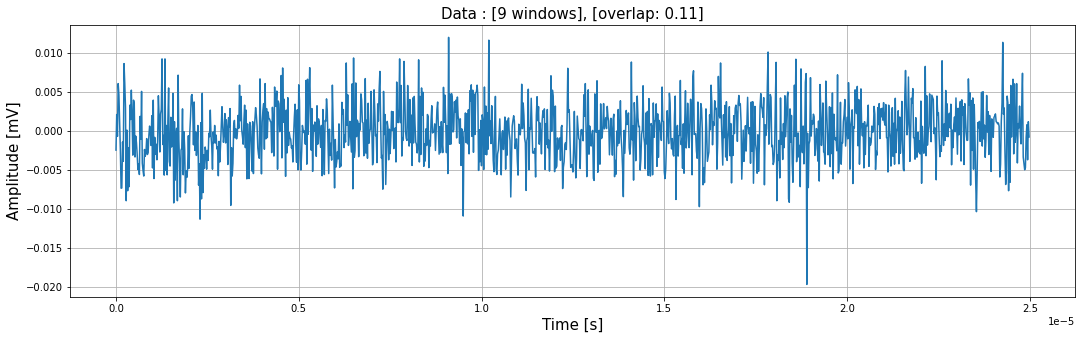

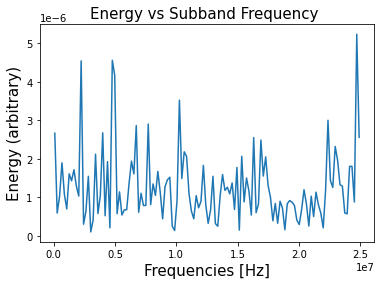

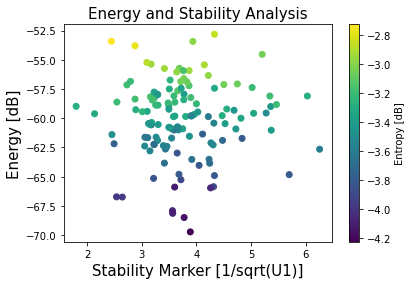

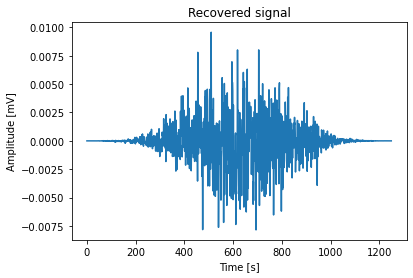

energy rec 3.080844084639521e-06


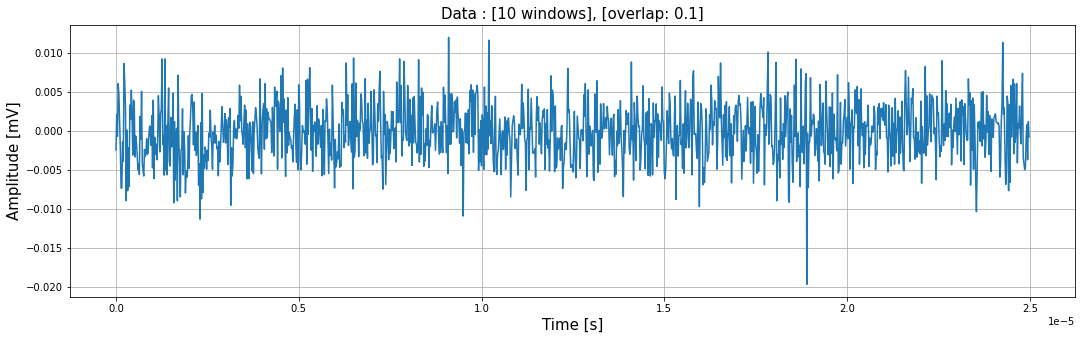

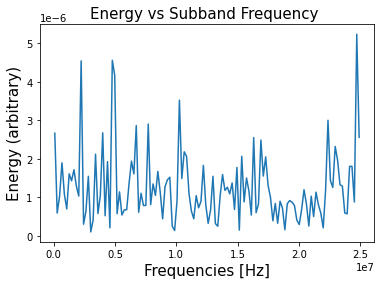

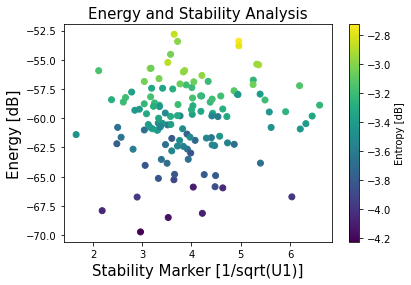

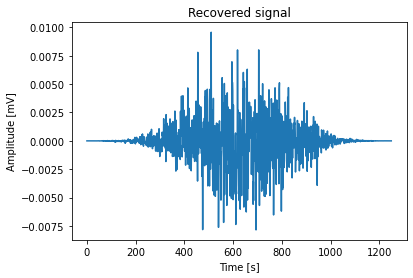

energy rec 3.080844084639521e-06


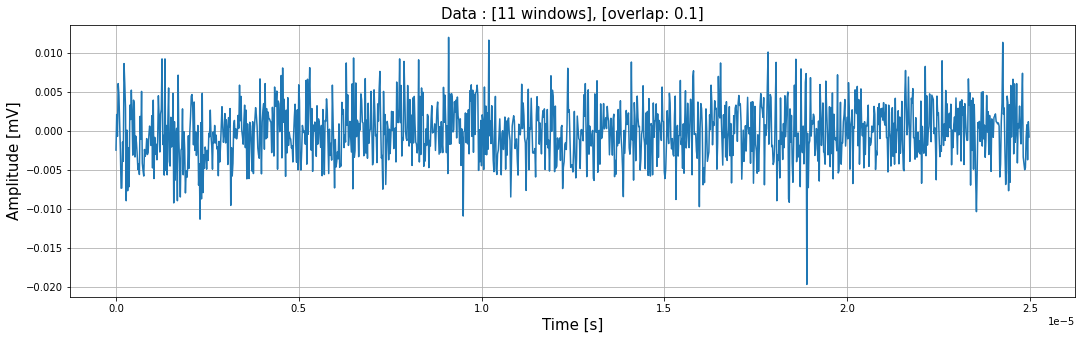

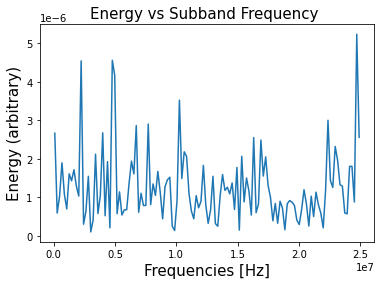

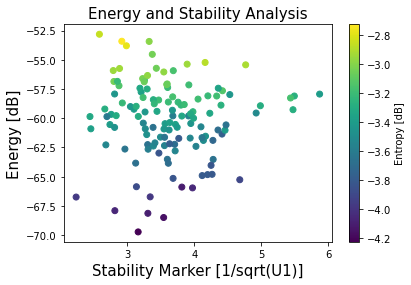

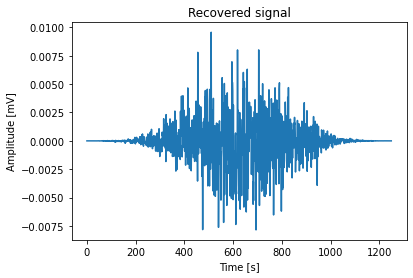

energy rec 3.080844084639521e-06


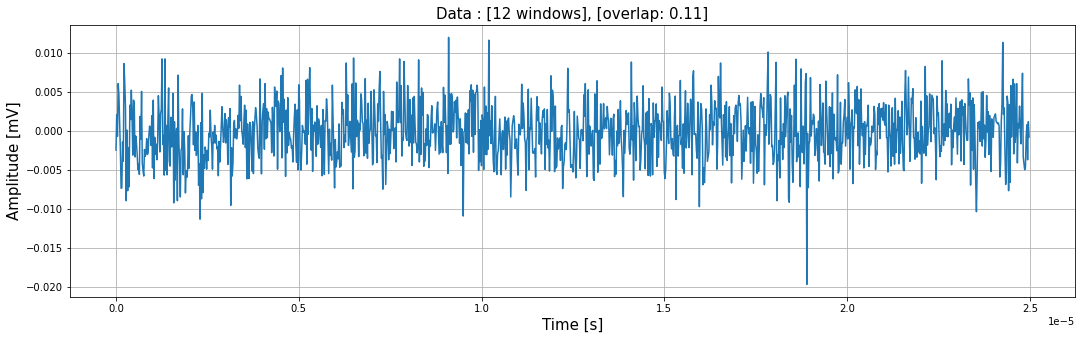

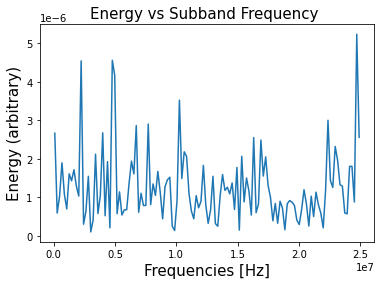

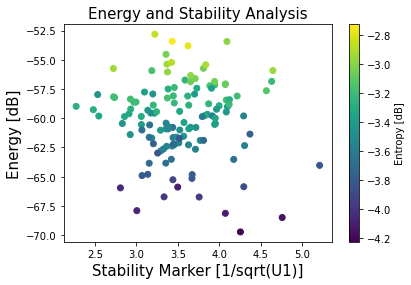

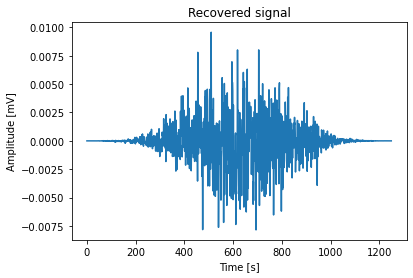

energy rec 3.080844084639521e-06


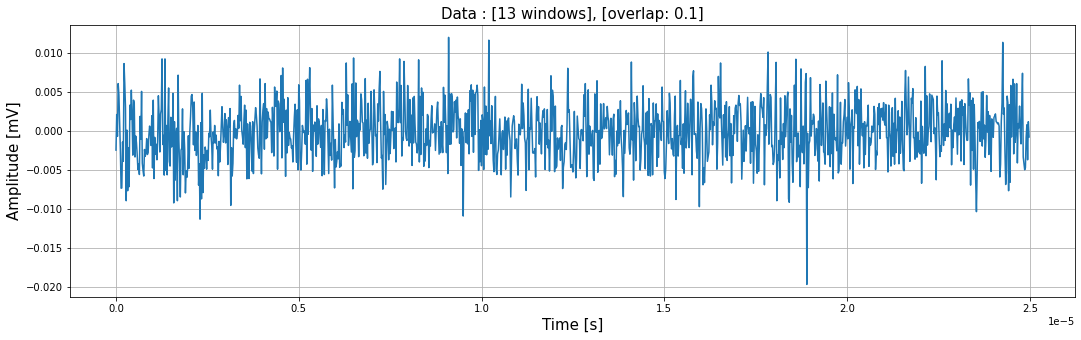

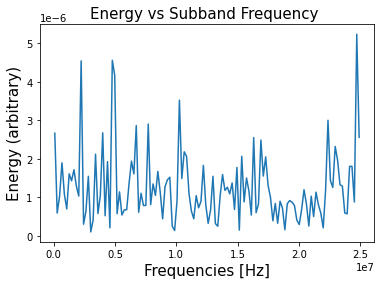

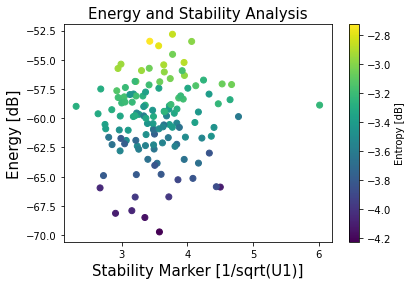

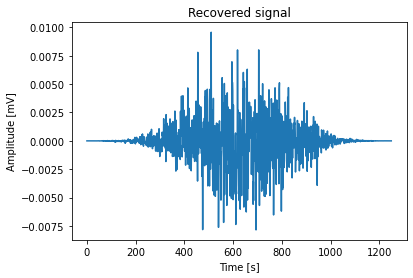

energy rec 3.080844084639521e-06


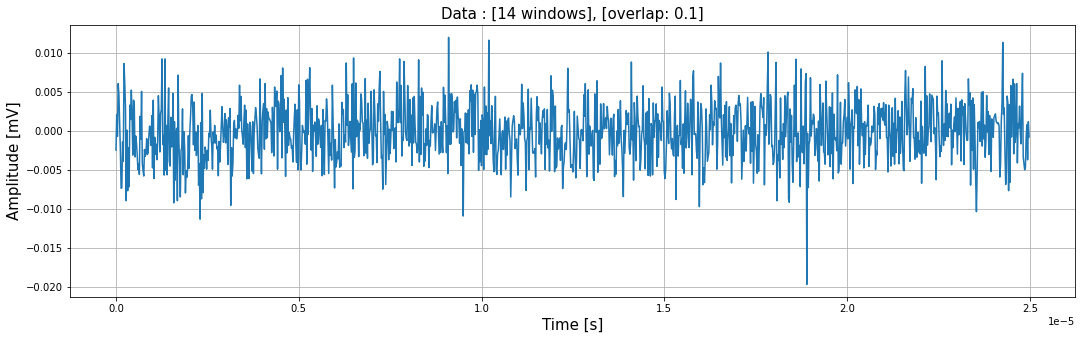

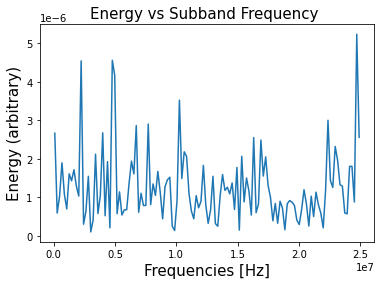

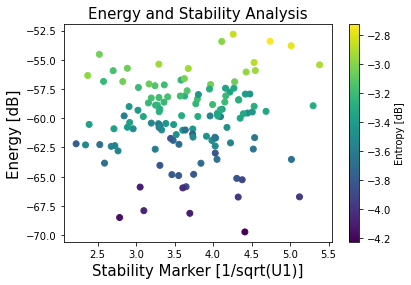

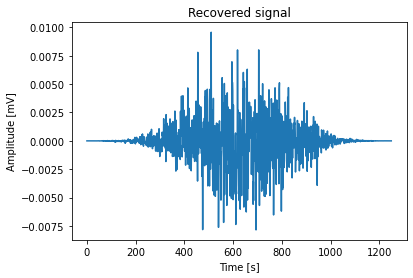

energy rec 3.080844084639521e-06


In [4]:
windows = 9
levels = 7
overlap = 0.1
wavelet = 'db10'
sampling_rate = int(50e6)

end = 1622
for i in [1500,1510]:
    num = f'{i}'
    file = r'C:\Users\maxau\OneDrive\Codes\WPT-Cavitation\docs\OneDrive_2023-04-25\PCD data - Test ID5 - 26-09-2022 - 2MHz - 34Wcm-2\C2test0'+num+'.txt'
    try:
        dfb=pd.read_csv(file, sep=',', header=None)  
    except FileNotFoundError:
        continue
    data = dfb.iloc[:,-1]
    time = dfb.iloc[:,-2]

    data += -np.average(data) # data centred around the meam
    time += -time[0] # time starts at 0

    print(len(data))
    data = data[int(len(data)*26/100):int(len(data)*31/100)]
    time = time[:len(data)]

    # plot data
    plot_data = True
    if plot_data:
        print(i)
        fig,ax = plt.subplots()
        plot.plot_wave(data,time,ax)
        plt.show()

    for windows in range(2,15):
        SVD_object = SVD(data,windows,levels,overlap,wavelet,sampling_rate)

        # important parameters
        win_data_shape = SVD_object.windowed_data.shape

        # create plots to show windowed data
        win_len = SVD_object.windowed_data.shape[1]
        fig1,ax1 = plt.subplots()
        fig1.set_size_inches(18,5)
        plot.plot_wave(data,time,ax1,f': [{windows} windows], [overlap: {round(SVD_object.overlap,2)}]')
        blackman_window = np.blackman(win_len)
        zeros = np.zeros(data.shape)
        offset = 0

        plot_windows = False
        if plot_windows:
            for _ in range(windows): # plot windows
                time_plot = time[offset : offset + win_len]
                ax1.plot(time_plot, blackman_window)
                offset += SVD_object.offset
        plt.show()

        # wpt
        transform_object = wpt.dwpt(data * blackmanharris(len(data)), levels, wavelet)

        # plot energy against frequency band middle frequency
        plot_frequency = True
        if plot_frequency:
            plot.plot_energy_vs_freq(transform_object, sampling_rate)
            plt.show()

        # some useful functions
        def compute_shannon_entropy(data):
            '''
            Calculates the shannon entropy of an array.
            Same implementation as the matlab function wentropy.
            '''
            return -np.sum(data**2*np.log(data**2)) 
        
        # plot energy, entropy, and stability
        stability_markers = SVD_object.stability_marker

        energy = list(transform_object.info()["energy"])
        log_energy = 10 * np.log10(energy)

        entropy = []
        for node in transform_object.get_level(): # final level nodes
            reconstructed_wave = inv.inv_dwpt(transform_object, nodes=node)
            entropy.append(compute_shannon_entropy(reconstructed_wave))
        
        entropy = np.log10(entropy)
        fig2,ax2 = plt.subplots()
        im = ax2.scatter(stability_markers, log_energy, c=entropy)
        ax2.set_xlabel('Stability Marker [1/sqrt(U1)]', fontsize=15)
        ax2.set_ylabel('Energy [dB]', fontsize=15)
        ax2.set_title('Energy and Stability Analysis', fontsize=15)
        fig2.colorbar(im, ax=ax2, label='Entropy [dB]')
        plt.show()

        if i == 1500:
            dwpt_result_nodes = transform_object.packet_nodes_for_rec(max_energy=0.00001) # list all nodes at the final level
        else:
            dwpt_result_nodes = transform_object.get_level()
        dwpt_inverse = inv.inv_dwpt(transform_object)

        plt.plot(dwpt_inverse)
        plt.title('Recovered signal')
        plt.ylabel('Amplitude [mV]')
        plt.xlabel('Time [s]')
        plt.show()

        print('energy rec',1/len(dwpt_inverse)*sum(dwpt_inverse**2))

